# CellViT Inference and AI-Readiness Target Generation

This cleaned notebook keeps the main setup, inference, evaluation, and target-generation workflow from the supplied notebook while removing standalone exploratory/debug cells and clearing old outputs.

## Important run guidance
- Run cells in order when setting up a fresh runtime.
- The notebook uses paths under `/content/drive/MyDrive/AI_Readiness_Project`.
- Processing cells may perform long-running inference and write results to Google Drive.
- **Do not rerun full inference or target-generation cells if their outputs already exist**, unless you intend to regenerate them. Prefer the missing-item recovery cells when appropriate.
- Check the path variables and existing output counts before running any processing cell.
- This notebook has not been executed end-to-end against your Drive, so verify outputs and metrics after running.


## 1. Environment setup

In [ ]:
# Optional dependency repair (run only if the runtime has a NumPy compatibility issue):
# %pip install --force-reinstall --no-cache-dir numpy==1.26.4
# Restart the runtime after changing NumPy, if required.

## 2. Project paths and configuration

In [ ]:
# ==========================================================
# CELL 1
# AI Readiness + CellViT Evaluation
# Project Setup
# ==========================================================

from google.colab import drive
import os
import random
import numpy as np
import pandas as pd
import torch

###############################################################
# Mount Google Drive
###############################################################

drive.mount('/content/drive')

###############################################################
# Project Root
###############################################################

PROJECT_ROOT = "/content/drive/MyDrive/AI_Readiness_Project"

###############################################################
# Dataset
###############################################################

DATASET_ROOT = os.path.join(PROJECT_ROOT, "AI_Readiness_Dataset")

ORIGINAL_DIR = os.path.join(DATASET_ROOT, "original")
DEGRADED_DIR = os.path.join(DATASET_ROOT, "degraded")

METADATA_CSV = os.path.join(DATASET_ROOT, "metadata.csv")

###############################################################
# Results Directory
###############################################################

RESULTS_ROOT = os.path.join(PROJECT_ROOT, "CellViT_Results")

PRED_ORIGINAL = os.path.join(RESULTS_ROOT, "Original_Predictions")
PRED_DEGRADED = os.path.join(RESULTS_ROOT, "Degraded_Predictions")

SEG_MASKS = os.path.join(RESULTS_ROOT, "Segmentation_Masks")
CLASS_RESULTS = os.path.join(RESULTS_ROOT, "Classification")

OVERLAYS = os.path.join(RESULTS_ROOT, "Overlay_Images")
VISUALIZATIONS = os.path.join(RESULTS_ROOT, "Visualizations")

METRICS = os.path.join(RESULTS_ROOT, "Metrics")

CSV_RESULTS = os.path.join(RESULTS_ROOT, "CSV")

BENCHMARK = os.path.join(RESULTS_ROOT, "Benchmark")

LOGS = os.path.join(RESULTS_ROOT, "Logs")

###############################################################
# Models
###############################################################

MODELS_ROOT = os.path.join(PROJECT_ROOT, "Models")

HF_MODEL_DIR = os.path.join(MODELS_ROOT, "HuggingFace_CellViT")

###############################################################
# Create Directories
###############################################################

folders = [

    RESULTS_ROOT,

    PRED_ORIGINAL,
    PRED_DEGRADED,

    SEG_MASKS,

    CLASS_RESULTS,

    OVERLAYS,

    VISUALIZATIONS,

    METRICS,

    CSV_RESULTS,

    BENCHMARK,

    LOGS,

    MODELS_ROOT,

    HF_MODEL_DIR

]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

###############################################################
# Runtime Configuration
###############################################################

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 8

NUM_WORKERS = 2

IMAGE_SIZE = 256

SEED = 42

###############################################################
# Reproducibility
###############################################################

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

###############################################################
# Verify Dataset
###############################################################

assert os.path.exists(DATASET_ROOT), "Dataset folder not found!"

assert os.path.exists(METADATA_CSV), "metadata.csv not found!"

assert len(os.listdir(ORIGINAL_DIR)) > 0, "Original folder empty!"

assert len(os.listdir(DEGRADED_DIR)) > 0, "Degraded folder empty!"

###############################################################
# Load Metadata
###############################################################

metadata = pd.read_csv(METADATA_CSV)

###############################################################
# Display Information
###############################################################

print("="*70)
print("AI READINESS + CELLVIT BENCHMARK")
print("="*70)

print(f"Device               : {DEVICE}")
print(f"PyTorch Version      : {torch.__version__}")

print(f"\nDataset")
print(f"Original Images      : {len(os.listdir(ORIGINAL_DIR))}")
print(f"Degraded Images      : {len(os.listdir(DEGRADED_DIR))}")

print(f"\nMetadata Rows        : {len(metadata)}")

print(f"\nResults Folder")
print(RESULTS_ROOT)

print("="*70)
print("Project Initialized Successfully")
print("="*70)

## 3. Install dependencies

In [ ]:
# ==========================================================
# CELL 2
# Install CellSeg Models PyTorch
# ==========================================================

import sys
import subprocess

print("="*70)
print("INSTALLING CELLSEG MODELS")
print("="*70)

packages = [

    "cellseg_models_pytorch",
    "datasets",
    "albumentations",
    "matplotlib",
    "opencv-python-headless"

]

for package in packages:

    try:

        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package]
        )

        print(f"✓ {package}")

    except Exception as e:

        print(f"✗ {package}")

        print(e)

print("\nVerifying Imports...\n")

try:

    import torch

    import cv2

    import numpy as np

    from datasets import load_dataset

    from albumentations import Compose, Resize

    from cellseg_models_pytorch.models.cellvit import CellVit

    from cellseg_models_pytorch.transforms.albu_transforms import (
        MinMaxNormalization,
    )

    print("✓ All imports successful")

except Exception as e:

    print(e)

print("\nTorch :", torch.__version__)
print("CUDA :", torch.cuda.is_available())

if torch.cuda.is_available():

    print(torch.cuda.get_device_name(0))

## 4. Load pretrained CellViT model

In [ ]:
# ==========================================================
# CELL 3
# Load Pretrained CellViT
# ==========================================================

import torch

from cellseg_models_pytorch.models.cellvit import CellVit

print("="*70)
print("LOADING CELLVIT MODEL")
print("="*70)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_NAME = "hgsc_v1_efficientnet_b5"

print("Downloading / Loading pretrained model...")

model = CellVit.from_pretrained(
    MODEL_NAME
)

model.set_inference_mode(
    mixed_precision=False
)

model.set_inference_mode(
    mixed_precision=False
)

print(type(model))

print(model)

print("\n")
print("="*70)
print("MODEL LOADED SUCCESSFULLY")
print("="*70)

print("Model :", MODEL_NAME)
print("Device:", DEVICE)
print("="*70)

## 5. Test model on one image

In [ ]:
# ==========================================================
# CELL 4
# Test CellViT on One Image
# ==========================================================

import os
import cv2
import matplotlib.pyplot as plt

###############################################################
# Select one image
###############################################################

image_name = sorted(os.listdir(ORIGINAL_DIR))[0]

image_path = os.path.join(ORIGINAL_DIR, image_name)

print("Image :", image_name)

###############################################################
# Read image
###############################################################

image = cv2.imread(image_path)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Shape :", image.shape)

###############################################################
# Run CellViT
###############################################################

prediction = model.predict(image)

###############################################################
# Display output information
###############################################################

print("\nPrediction Type :", type(prediction))

if isinstance(prediction, dict):

    print("\nPrediction Keys")

    for k in prediction.keys():

        print("-", k)

else:

    print(prediction)

###############################################################
# Show Image
###############################################################

plt.figure(figsize=(6,6))

plt.imshow(image)

plt.axis("off")

plt.title(image_name)

plt.show()

## Workflow step

In [ ]:
# ==========================================================
# CELL 5
# Inspect CellViT Prediction Structure
# ==========================================================

import numpy as np

prediction = model.predict(image)

print("="*70)
print("PREDICTION STRUCTURE")
print("="*70)

for key, value in prediction.items():

    print(f"\n===== {key.upper()} =====")

    print("Type :", type(value))

    if isinstance(value, np.ndarray):

        print("Shape :", value.shape)
        print("Dtype :", value.dtype)
        print("Min   :", value.min())
        print("Max   :", value.max())

    elif isinstance(value, dict):

        print("Dictionary Keys:")

        for k, v in value.items():

            print(f"  {k} -> {type(v)}")

            if isinstance(v, np.ndarray):

                print("     Shape :", v.shape)
                print("     Dtype :", v.dtype)
                print("     Min   :", v.min())
                print("     Max   :", v.max())

    elif isinstance(value, list):

        print("Length :", len(value))

        if len(value):

            print("First element type :", type(value[0]))

    else:

        print(value)

## 6. Inspect post-processed output

In [ ]:
# ==========================================================
# CELL 6 — Inspect Post-Processed CellViT Output
# ==========================================================

result = model.post_process(
    prediction,
    use_async_postproc=False
)

print("="*70)
print("POST-PROCESSING OUTPUT")
print("="*70)

for key, value in result.items():

    print(f"\n{'='*50}")
    print(key.upper())
    print(f"{'='*50}")

    print("Type :", type(value))

    # ------------------------------------------------------
    # None output
    # ------------------------------------------------------

    if value is None:

        print("Value : None")
        continue

    # ------------------------------------------------------
    # List output
    # ------------------------------------------------------

    if isinstance(value, list):

        print("Length :", len(value))

        if len(value) == 0:
            continue

        item = value[0]

        print("First element type :", type(item))

        # --------------------------------------------------
        # Tuple output
        # --------------------------------------------------

        if isinstance(item, tuple):

            print("Tuple length :", len(item))

            for i, element in enumerate(item):

                print(f"\nTuple Element {i}")

                print("Type :", type(element))

                if isinstance(element, np.ndarray):

                    print("Shape :", element.shape)
                    print("dtype :", element.dtype)
                    print(
                        "Unique values :",
                        len(np.unique(element))
                    )

                    print(
                        "Min :",
                        element.min(),
                        "Max :",
                        element.max()
                    )

        # --------------------------------------------------
        # Direct NumPy output
        # --------------------------------------------------

        elif isinstance(item, np.ndarray):

            print("Shape :", item.shape)
            print("dtype :", item.dtype)

    # ------------------------------------------------------
    # Direct NumPy output
    # ------------------------------------------------------

    elif isinstance(value, np.ndarray):

        print("Shape :", value.shape)
        print("dtype :", value.dtype)

## 7. Define inference and visualization helpers

In [ ]:
# ==========================================================
# CELL 8
# CellViT Inference Function
# ==========================================================

import os
import cv2
import json
import time
import numpy as np
import matplotlib.pyplot as plt

###############################################################
# Helper Function
###############################################################

def create_overlay(image, instance_map, alpha=0.45):
    """
    Overlay instance segmentation on RGB image.
    """

    image = image.copy()

    colored = np.zeros_like(image)

    ids = np.unique(instance_map)

    np.random.seed(42)

    colors = {
        idx: np.random.randint(0,255,3)
        for idx in ids if idx != 0
    }

    for idx in ids:

        if idx == 0:
            continue

        colored[instance_map==idx] = colors[idx]

    overlay = cv2.addWeighted(
        image,
        1-alpha,
        colored,
        alpha,
        0
    )

    return overlay

###############################################################
# Main Inference Function
###############################################################

def run_cellvit(image_path,
                save_dir=None,
                save_visualization=True):

    ###########################################################
    # Read Image
    ###########################################################

    image = cv2.imread(image_path)

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    ###########################################################
    # Inference
    ###########################################################

    start = time.time()

    prediction = model.predict(image)

    prediction = model.post_process(
        prediction,
        use_async_postproc=False
    )

    runtime = time.time()-start

    ###########################################################
    # Extract Outputs
    ###########################################################

    instance_map = prediction["nuc"][0][0]

    type_map = prediction["nuc"][0][1]

    ###########################################################
    # Statistics
    ###########################################################

    cell_ids = np.unique(instance_map)

    cell_ids = cell_ids[cell_ids!=0]

    statistics = {

        "image_name": os.path.basename(image_path),

        "height": int(image.shape[0]),

        "width": int(image.shape[1]),

        "num_cells": int(len(cell_ids)),

        "num_classes": int(len(np.unique(type_map))-1),

        "cell_classes":
            np.unique(type_map).tolist(),

        "runtime_seconds":
            round(runtime,4)

    }

    ###########################################################
    # Overlay
    ###########################################################

    overlay = create_overlay(
        image,
        instance_map
    )

    ###########################################################
    # Save
    ###########################################################

    if save_dir is not None:

        os.makedirs(save_dir, exist_ok=True)

        np.save(
            os.path.join(
                save_dir,
                "instance_map.npy"
            ),
            instance_map
        )

        np.save(
            os.path.join(
                save_dir,
                "type_map.npy"
            ),
            type_map
        )

        cv2.imwrite(

            os.path.join(
                save_dir,
                "overlay.png"
            ),

            cv2.cvtColor(
                overlay,
                cv2.COLOR_RGB2BGR
            )

        )

        with open(

            os.path.join(
                save_dir,
                "statistics.json"
            ),

            "w"

        ) as f:

            json.dump(
                statistics,
                f,
                indent=4
            )

    ###########################################################
    # Display
    ###########################################################

    if save_visualization:

        plt.figure(figsize=(18,6))

        plt.subplot(131)
        plt.imshow(image)
        plt.title("Original")
        plt.axis("off")

        plt.subplot(132)
        plt.imshow(instance_map,
                   cmap="nipy_spectral")
        plt.title("Instance Map")
        plt.axis("off")

        plt.subplot(133)
        plt.imshow(overlay)
        plt.title("Overlay")
        plt.axis("off")

        plt.show()

    ###########################################################
    # Return
    ###########################################################

    return {

        "instance_map": instance_map,

        "type_map": type_map,

        "statistics": statistics,

        "overlay": overlay

    }

print("="*70)
print("Inference Function Created Successfully")
print("="*70)

## 8. Validate inference and save a single example

In [ ]:
# ==========================================================
# CELL 9
# Test Inference + Save Outputs for One Image
# ==========================================================

import os

###############################################################
# Select First Image
###############################################################

image_name = sorted(os.listdir(ORIGINAL_DIR))[0]

image_path = os.path.join(
    ORIGINAL_DIR,
    image_name
)

###############################################################
# Output Folder
###############################################################

save_folder = os.path.join(

    PRED_ORIGINAL,

    os.path.splitext(image_name)[0]

)

###############################################################
# Run CellViT
###############################################################

output = run_cellvit(

    image_path=image_path,

    save_dir=save_folder,

    save_visualization=True

)

###############################################################
# Display Statistics
###############################################################

print("\n")
print("="*70)
print("INFERENCE COMPLETED")
print("="*70)

for k, v in output["statistics"].items():

    print(f"{k:<20}: {v}")

print("="*70)

###############################################################
# Verify Saved Files
###############################################################

print("\nSaved Files:\n")

for file in sorted(os.listdir(save_folder)):

    print("✓", file)

print("\nFolder Location:")
print(save_folder)

print("="*70)

## 9. Run inference on original images

In [ ]:
# ==========================================================
# CELL 10
# Process All Original Images
# ==========================================================

from tqdm import tqdm
import traceback
import os
import json
import numpy as np

###############################################################
# Logs
###############################################################

failed_images = []

processed = 0
skipped = 0

###############################################################
# Image List
###############################################################

image_list = sorted(os.listdir(ORIGINAL_DIR))

print("="*70)
print("PROCESSING ORIGINAL DATASET")
print("="*70)
print("Total Images :", len(image_list))
print()

###############################################################
# Loop
###############################################################

for image_name in tqdm(image_list):

    image_path = os.path.join(
        ORIGINAL_DIR,
        image_name
    )

    save_folder = os.path.join(
        PRED_ORIGINAL,
        os.path.splitext(image_name)[0]
    )

    ###########################################################
    # Resume Support
    ###########################################################

    if os.path.exists(
        os.path.join(
            save_folder,
            "statistics.json"
        )
    ):

        skipped += 1
        continue

    ###########################################################
    # Inference
    ###########################################################

    try:

        output = run_cellvit(

            image_path=image_path,

            save_dir=save_folder,

            save_visualization=False

        )

        #######################################################
        # Save compressed prediction
        #######################################################

        np.savez_compressed(

            os.path.join(
                save_folder,
                "prediction.npz"
            ),

            instance_map=output["instance_map"],

            type_map=output["type_map"]

        )

        processed += 1

    except Exception as e:

        failed_images.append({

            "image": image_name,

            "error": str(e)

        })

###############################################################
# Save Error Log
###############################################################

with open(

    os.path.join(
        LOGS,
        "original_failed_images.json"
    ),

    "w"

) as f:

    json.dump(
        failed_images,
        f,
        indent=4
    )

###############################################################
# Final Report
###############################################################

print("\n")
print("="*70)
print("ORIGINAL DATASET FINISHED")
print("="*70)

print("Processed :", processed)
print("Skipped   :", skipped)
print("Failed    :", len(failed_images))

print("\nFailure Log")

print(
    os.path.join(
        LOGS,
        "original_failed_images.json"
    )
)

print("="*70)

## 10. Run inference on degraded images

In [ ]:
# ==========================================================
# CELL 11
# Process All Degraded Images
# ==========================================================

from tqdm import tqdm
import os
import json

###############################################################
# Logs
###############################################################

failed_images = []

processed = 0
skipped = 0

###############################################################
# Image List
###############################################################

image_list = sorted(os.listdir(DEGRADED_DIR))

print("="*70)
print("PROCESSING DEGRADED DATASET")
print("="*70)

print("Total Images :", len(image_list))
print()

###############################################################
# Loop
###############################################################

for image_name in tqdm(image_list):

    image_path = os.path.join(
        DEGRADED_DIR,
        image_name
    )

    save_folder = os.path.join(
        PRED_DEGRADED,
        os.path.splitext(image_name)[0]
    )

    ###########################################################
    # Resume Support
    ###########################################################

    if os.path.exists(
        os.path.join(
            save_folder,
            "statistics.json"
        )
    ):

        skipped += 1
        continue

    ###########################################################
    # Inference
    ###########################################################

    try:

        output = run_cellvit(

            image_path=image_path,

            save_dir=save_folder,

            save_visualization=False

        )

        #######################################################
        # Save compressed prediction
        #######################################################

        np.savez_compressed(

            os.path.join(
                save_folder,
                "prediction.npz"
            ),

            instance_map=output["instance_map"],

            type_map=output["type_map"]

        )

        processed += 1

    except Exception as e:

        failed_images.append({

            "image": image_name,

            "error": str(e)

        })

###############################################################
# Save Failure Log
###############################################################

failure_log = os.path.join(
    LOGS,
    "degraded_failed_images.json"
)

with open(failure_log, "w") as f:

    json.dump(
        failed_images,
        f,
        indent=4
    )

###############################################################
# Final Report
###############################################################

print("\n")
print("="*70)
print("DEGRADED DATASET FINISHED")
print("="*70)

print("Processed :", processed)
print("Skipped   :", skipped)
print("Failed    :", len(failed_images))

print("\nFailure Log:")
print(failure_log)

print("="*70)

## 11. Recover missing original predictions

In [ ]:
# ==========================================================
# PROCESS ONLY MISSING ORIGINAL IMAGES
# ==========================================================

from tqdm import tqdm
import traceback
import os
import json
import numpy as np

###############################################################
# Logs
###############################################################

failed_images = []

processed = 0
skipped = 0

###############################################################
# 1. GET ALL IMAGE NAMES
###############################################################

image_list = sorted(
    os.listdir(ORIGINAL_DIR),
    key=lambda x: int(os.path.splitext(x)[0])
)

###############################################################
# 2. GET ALL DEGRADED IMAGE IDS
#
# We use the completed degraded dataset as the master list.
# Therefore every degraded image must eventually have a
# corresponding original CellViT result.
###############################################################

degraded_folders = sorted(
    [
        folder
        for folder in os.listdir(DEGRADED_RESULTS_DIR)
        if os.path.isdir(
            os.path.join(
                DEGRADED_RESULTS_DIR,
                folder
            )
        )
    ],
    key=lambda x: int(x)
)

###############################################################
# 3. GET EXISTING ORIGINAL RESULTS
###############################################################

existing_original_ids = set()

for folder in os.listdir(PRED_ORIGINAL):

    folder_path = os.path.join(
        PRED_ORIGINAL,
        folder
    )

    if os.path.isdir(folder_path):

        statistics_path = os.path.join(
            folder_path,
            "statistics.json"
        )

        if os.path.exists(statistics_path):

            existing_original_ids.add(
                folder
            )

###############################################################
# 4. FIND ONLY MISSING ORIGINAL IMAGES
###############################################################

missing_ids = [
    image_id
    for image_id in degraded_folders
    if image_id not in existing_original_ids
]

missing_ids = sorted(
    missing_ids,
    key=lambda x: int(x)
)

###############################################################
# 5. PRINT SUMMARY
###############################################################

print("="*70)
print("MISSING ORIGINAL CELLVIT PREDICTIONS")
print("="*70)

print("Total degraded images :", len(degraded_folders))
print("Existing originals    :", len(existing_original_ids))
print("Missing originals     :", len(missing_ids))

print("\nFirst 20 missing IDs:")
print(missing_ids[:20])

print("\nLast 20 missing IDs:")
print(missing_ids[-20:])

print("="*70)

###############################################################
# 6. VERIFY EXPECTED COUNT
###############################################################

if len(missing_ids) != 1214:

    print(
        "\nWARNING:"
        f" Expected 1214 missing images, "
        f"but found {len(missing_ids)}."
    )

else:

    print("\n✓ Exactly 1214 missing images found.")

###############################################################
# 7. CREATE IMAGE LOOKUP
###############################################################

image_lookup = {}

for image_name in image_list:

    image_id = os.path.splitext(
        image_name
    )[0]

    image_lookup[image_id] = image_name

###############################################################
# 8. CHECK SOURCE IMAGES
###############################################################

missing_source_images = [
    image_id
    for image_id in missing_ids
    if image_id not in image_lookup
]

if missing_source_images:

    print(
        "\nMissing source images:"
    )

    print(
        missing_source_images[:20]
    )

    raise RuntimeError(
        "Some source images could not be found."
    )

###############################################################
# 9. PROCESS ONLY MISSING IMAGES
###############################################################

print("\n")
print("="*70)
print("PROCESSING ONLY MISSING ORIGINAL IMAGES")
print("="*70)

print(
    "Images to process :",
    len(missing_ids)
)

print()

for image_id in tqdm(
    missing_ids,
    desc="Missing Original Images"
):

    ###########################################################
    # Original image name
    ###########################################################

    image_name = image_lookup[
        image_id
    ]

    image_path = os.path.join(
        ORIGINAL_DIR,
        image_name
    )

    ###########################################################
    # Matching output folder
    #
    # Example:
    #
    # 06687
    # 06688
    # ...
    ###########################################################

    save_folder = os.path.join(
        PRED_ORIGINAL,
        image_id
    )

    ###########################################################
    # Resume support
    ###########################################################

    statistics_path = os.path.join(
        save_folder,
        "statistics.json"
    )

    if os.path.exists(
        statistics_path
    ):

        skipped += 1
        continue

    ###########################################################
    # CellViT inference
    #
    # IMPORTANT:
    # This is EXACTLY the same function used in your
    # original CellViT processing notebook.
    ###########################################################

    try:

        output = run_cellvit(

            image_path=image_path,

            save_dir=save_folder,

            save_visualization=False

        )

        #######################################################
        # Save compressed prediction
        #######################################################

        np.savez_compressed(

            os.path.join(
                save_folder,
                "prediction.npz"
            ),

            instance_map=output[
                "instance_map"
            ],

            type_map=output[
                "type_map"
            ]

        )

        processed += 1

    except Exception as e:

        failed_images.append({

            "image": image_name,

            "image_id": image_id,

            "error": str(e),

            "traceback": traceback.format_exc()

        })

        #######################################################
        # Save failure log continuously
        #######################################################

        with open(

            os.path.join(
                LOGS,
                "original_missing_failed_images.json"
            ),

            "w"

        ) as f:

            json.dump(
                failed_images,
                f,
                indent=4
            )

###############################################################
# 10. FINAL FAILURE LOG
###############################################################

with open(

    os.path.join(
        LOGS,
        "original_missing_failed_images.json"
    ),

    "w"

) as f:

    json.dump(
        failed_images,
        f,
        indent=4
    )

###############################################################
# 11. FINAL REPORT
###############################################################

print("\n")
print("="*70)
print("MISSING ORIGINAL DATASET FINISHED")
print("="*70)

print("Requested :", len(missing_ids))
print("Processed :", processed)
print("Skipped   :", skipped)
print("Failed    :", len(failed_images))

print("\nFailure Log:")

print(
    os.path.join(
        LOGS,
        "original_missing_failed_images.json"
    )
)

print("="*70)

## 12. Process missing original predictions

In [ ]:
# ==========================================================
# PROCESS ONLY THE 1214 MISSING ORIGINAL IMAGES
# ==========================================================

from tqdm import tqdm
import traceback
import os
import json
import numpy as np
import time

###############################################################
# Logs
###############################################################

failed_images = []

processed = 0
skipped = 0

###############################################################
# image_lookup already exists from previous cell
# missing_ids already exists from previous cell
###############################################################

print("=" * 70)
print("PROCESSING MISSING ORIGINAL CELLVIT IMAGES")
print("=" * 70)

print("Images to process :", len(missing_ids))
print("First ID         :", missing_ids[0])
print("Last ID          :", missing_ids[-1])

print()

###############################################################
# Loop ONLY over missing IDs
###############################################################

for image_id in tqdm(
    missing_ids,
    desc="Missing Original Images"
):

    ###########################################################
    # Get source image
    ###########################################################

    image_name = image_lookup[image_id]

    image_path = os.path.join(
        ORIGINAL_DIR,
        image_name
    )

    ###########################################################
    # Matching output folder
    ###########################################################

    save_folder = os.path.join(
        PRED_ORIGINAL,
        image_id
    )

    ###########################################################
    # Resume support
    ###########################################################

    statistics_path = os.path.join(
        save_folder,
        "statistics.json"
    )

    if os.path.exists(statistics_path):

        skipped += 1
        continue

    ###########################################################
    # Run CellViT
    ###########################################################

    try:

        output = run_cellvit(

            image_path=image_path,

            save_dir=save_folder,

            save_visualization=False

        )

        #######################################################
        # Save compressed prediction
        #######################################################

        np.savez_compressed(

            os.path.join(
                save_folder,
                "prediction.npz"
            ),

            instance_map=output["instance_map"],

            type_map=output["type_map"]

        )

        processed += 1

    except Exception as e:

        failed_images.append({

            "image": image_name,

            "image_id": image_id,

            "error": str(e),

            "traceback": traceback.format_exc()

        })

        #######################################################
        # Save failure log immediately
        #######################################################

        with open(

            os.path.join(
                LOGS,
                "original_missing_failed_images.json"
            ),

            "w"

        ) as f:

            json.dump(
                failed_images,
                f,
                indent=4
            )


###############################################################
# Save final failure log
###############################################################

with open(

    os.path.join(
        LOGS,
        "original_missing_failed_images.json"
    ),

    "w"

) as f:

    json.dump(
        failed_images,
        f,
        indent=4
    )


###############################################################
# Final report
###############################################################

print("\n")
print("=" * 70)
print("MISSING ORIGINAL DATASET FINISHED")
print("=" * 70)

print("Requested :", len(missing_ids))
print("Processed :", processed)
print("Skipped   :", skipped)
print("Failed    :", len(failed_images))

print("\nFailure Log:")
print(
    os.path.join(
        LOGS,
        "original_missing_failed_images.json"
    )
)

print("=" * 70)

## 13. Verify image pairs and locate ground truth

In [ ]:
# ============================================================
# CELL 14
# VERIFY ORIGINAL/DEGRADED PAIRS
# + LOCATE PANNUKE GROUND TRUTH
# ============================================================

import os
import json
import yaml
import numpy as np
from pathlib import Path

print("=" * 80)
print("PAIRING + PANNUKE GROUND-TRUTH VALIDATION")
print("=" * 80)


# ============================================================
# PART A — VERIFY ORIGINAL / DEGRADED PAIRS
# ============================================================

print("\n" + "-" * 80)
print("PART A — ORIGINAL / DEGRADED PAIR VALIDATION")
print("-" * 80)

RESULTS_ROOT = Path(
    "/content/drive/MyDrive/AI_Readiness_Project/CellViT_Results"
)

ORIGINAL_RESULTS_DIR = (
    RESULTS_ROOT / "Original_Predictions"
)

DEGRADED_RESULTS_DIR = (
    RESULTS_ROOT / "Degraded_Predictions"
)

# Source images used for CellViT
ORIGINAL_DIR = Path(
    "/content/drive/MyDrive/AI_Readiness_Project/AI_Readiness_Dataset/original"
)

# ------------------------------------------------------------
# Get result IDs
# ------------------------------------------------------------

original_ids = {
    p.name
    for p in ORIGINAL_RESULTS_DIR.iterdir()
    if p.is_dir()
}

degraded_ids = {
    p.name
    for p in DEGRADED_RESULTS_DIR.iterdir()
    if p.is_dir()
}

common_ids = sorted(
    original_ids & degraded_ids,
    key=lambda x: int(x)
)

print("Original result IDs :", len(original_ids))
print("Degraded result IDs :", len(degraded_ids))
print("Common pairs :", len(common_ids))


# ------------------------------------------------------------
# Verify statistics.json image_name
# for both original and degraded results
# ------------------------------------------------------------

pair_failures = []

# Check first, middle, last + random samples
sample_ids = []

if common_ids:

    sample_ids.extend(
        common_ids[:5]
    )

    sample_ids.extend(
        common_ids[-5:]
    )

    if len(common_ids) > 20:

        sample_ids.extend(
            common_ids[
                len(common_ids)//2 - 2 :
                len(common_ids)//2 + 3
            ]
        )

# Remove duplicates
sample_ids = sorted(
    set(sample_ids),
    key=lambda x: int(x)
)

print(
    "\nChecking sample pair IDs:",
    sample_ids
)


for image_id in sample_ids:

    original_folder = (
        ORIGINAL_RESULTS_DIR / image_id
    )

    degraded_folder = (
        DEGRADED_RESULTS_DIR / image_id
    )

    try:

        # ----------------------------------------------------
        # Read original statistics
        # ----------------------------------------------------

        with open(
            original_folder / "statistics.json",
            "r"
        ) as f:

            original_stats = json.load(f)

        # ----------------------------------------------------
        # Read degraded statistics
        # ----------------------------------------------------

        with open(
            degraded_folder / "statistics.json",
            "r"
        ) as f:

            degraded_stats = json.load(f)

        expected_name = f"{image_id}.png"

        original_name_ok = (
            original_stats.get("image_name")
            == expected_name
        )

        degraded_name_ok = (
            degraded_stats.get("image_name")
            == expected_name
        )

        # ----------------------------------------------------
        # Load maps and verify same spatial dimensions
        # ----------------------------------------------------

        original_instance = np.load(
            original_folder / "instance_map.npy",
            allow_pickle=False
        )

        degraded_instance = np.load(
            degraded_folder / "instance_map.npy",
            allow_pickle=False
        )

        original_type = np.load(
            original_folder / "type_map.npy",
            allow_pickle=False
        )

        degraded_type = np.load(
            degraded_folder / "type_map.npy",
            allow_pickle=False
        )

        shapes_ok = (
            original_instance.shape
            == degraded_instance.shape
            == original_type.shape
            == degraded_type.shape
        )

        # ----------------------------------------------------
        # Check source image exists
        # ----------------------------------------------------

        source_image = (
            ORIGINAL_DIR / expected_name
        )

        source_exists = source_image.exists()

        # ----------------------------------------------------
        # Record failures
        # ----------------------------------------------------

        if not (
            original_name_ok
            and degraded_name_ok
            and shapes_ok
            and source_exists
        ):

            pair_failures.append({
                "image_id": image_id,
                "original_statistics_name":
                    original_stats.get("image_name"),
                "degraded_statistics_name":
                    degraded_stats.get("image_name"),
                "shapes": {
                    "original_instance":
                        original_instance.shape,
                    "degraded_instance":
                        degraded_instance.shape,
                    "original_type":
                        original_type.shape,
                    "degraded_type":
                        degraded_type.shape
                },
                "source_exists":
                    source_exists
            })

        print(
            f"{image_id} | "
            f"original={original_stats.get('image_name')} | "
            f"degraded={degraded_stats.get('image_name')} | "
            f"shape={original_instance.shape} | "
            f"{'OK' if not pair_failures or pair_failures[-1].get('image_id') != image_id else 'FAIL'}"
        )

    except Exception as e:

        pair_failures.append({
            "image_id": image_id,
            "error": str(e)
        })

        print(
            f"{image_id} | ERROR: {e}"
        )


# ------------------------------------------------------------
# Pairing conclusion
# ------------------------------------------------------------

print("\nPairing validation failures:")
print(len(pair_failures))

if len(pair_failures) == 0:

    print(
        "✓ Sampled original/degraded pairs are correctly matched."
    )

else:

    print(
        "⚠ Pairing issues detected:"
    )

    for failure in pair_failures:
        print(failure)


# ============================================================
# PART B — LOCATE CELLVIT PANNUKE CONFIGURATION
# ============================================================

print("\n" + "-" * 80)
print("PART B — LOCATING PANNUKE CONFIGURATION")
print("-" * 80)

CELLVIT_ROOT = Path(
    "/content/CellViT"
)

candidate_configs = []

if CELLVIT_ROOT.exists():

    for config_path in CELLVIT_ROOT.rglob("config.yaml"):

        try:

            with open(
                config_path,
                "r"
            ) as f:

                text = f.read().lower()

            if "pannuke" in text:

                candidate_configs.append(
                    config_path
                )

        except Exception:
            pass


print(
    "PanNuke-related config files found:",
    len(candidate_configs)
)

for path in candidate_configs[:20]:
    print("-", path)


# ============================================================
# PART C — EXTRACT DATASET PATH
# ============================================================

PANNUKE_DATASET_PATH = None
PANNUKE_RUN_CONFIG = None

for config_path in candidate_configs:

    try:

        with open(
            config_path,
            "r"
        ) as f:

            config = yaml.safe_load(f)

        # ----------------------------------------------------
        # Expected CellViT structure:
        #
        # data:
        #     dataset_path: ...
        # ----------------------------------------------------

        if (
            isinstance(config, dict)
            and "data" in config
            and isinstance(config["data"], dict)
            and "dataset_path" in config["data"]
        ):

            PANNUKE_DATASET_PATH = Path(
                str(config["data"]["dataset_path"])
            )

            PANNUKE_RUN_CONFIG = config_path

            break

    except Exception:
        pass


print("\nDataset configuration:")

if PANNUKE_DATASET_PATH is None:

    print(
        "⚠ Could not automatically extract dataset_path."
    )

else:

    print(
        "✓ Run configuration:",
        PANNUKE_RUN_CONFIG
    )

    print(
        "✓ PanNuke dataset path:",
        PANNUKE_DATASET_PATH
    )

    print(
        "✓ Path exists:",
        PANNUKE_DATASET_PATH.exists()
    )


# ============================================================
# PART D — INSPECT PANNUKE TOP-LEVEL STRUCTURE
# ============================================================

if PANNUKE_DATASET_PATH is not None:

    if PANNUKE_DATASET_PATH.exists():

        print(
            "\n" + "-" * 80
        )
        print(
            "PANNUKE DATASET STRUCTURE"
        )
        print(
            "-" * 80
        )

        top_items = sorted(
            PANNUKE_DATASET_PATH.iterdir(),
            key=lambda x: x.name
        )

        for item in top_items[:50]:

            if item.is_dir():
                print(
                    "[DIR ]",
                    item.name
                )

            else:
                print(
                    "[FILE]",
                    item.name
                )

    else:

        print(
            "\n⚠ PanNuke path does not exist in this runtime."
        )


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("VALIDATION SUMMARY")
print("=" * 80)

print(
    "Complete original/degraded pairs:",
    len(common_ids)
)

print(
    "Sample pairing failures:",
    len(pair_failures)
)

if (
    len(common_ids) == 7901
    and len(pair_failures) == 0
):

    print(
        "\n✓ ORIGINAL / DEGRADED PAIRING PASSED"
    )

else:

    print(
        "\n⚠ PAIRING VALIDATION NEEDS ATTENTION"
    )

if PANNUKE_DATASET_PATH is not None:
    print(
        "✓ PanNuke dataset path identified"
    )
else:
    print(
        "⚠ PanNuke dataset path still needs identification"
    )

print("=" * 80)

## 14. Load PanNuke ground truth

In [ ]:
# ============================================================
# CELL 15 — LOAD PANNUKE GROUND TRUTH
#             USING fold1 + fold2 + fold3
# ============================================================

from datasets import load_dataset, concatenate_datasets
import numpy as np

print("=" * 80)
print("LOADING PANNUKE GROUND TRUTH")
print("=" * 80)


# ============================================================
# 1. LOAD ALL THREE PANNUKE FOLDS
# ============================================================

print("\nLoading fold1...")
fold1 = load_dataset(
    "RationAI/PanNuke",
    split="fold1"
)

print("fold1 samples:", len(fold1))


print("\nLoading fold2...")
fold2 = load_dataset(
    "RationAI/PanNuke",
    split="fold2"
)

print("fold2 samples:", len(fold2))


print("\nLoading fold3...")
fold3 = load_dataset(
    "RationAI/PanNuke",
    split="fold3"
)

print("fold3 samples:", len(fold3))


# ============================================================
# 2. COMBINE FOLDS
# ============================================================

dataset = concatenate_datasets([
    fold1,
    fold2,
    fold3
])

print("\n" + "-" * 80)
print("COMBINED DATASET")
print("-" * 80)

print("Total samples:", len(dataset))

if len(dataset) == 7901:
    print("✓ Dataset contains exactly 7901 images.")
else:
    print(
        "⚠ Expected 7901 images, "
        f"but found {len(dataset)}."
    )


# ============================================================
# 3. SHOW DATASET FEATURES
# ============================================================

print("\nDataset columns:")
print(dataset.column_names)


# ============================================================
# 4. LOAD FIRST SAMPLE
# ============================================================

sample = dataset[0]

print("\n" + "-" * 80)
print("FIRST SAMPLE")
print("-" * 80)

print("Keys:")
print(sample.keys())


# ============================================================
# 5. IMAGE
# ============================================================

image = np.array(
    sample["image"].convert("RGB")
)

print("\nImage:")
print("Shape :", image.shape)
print("Dtype :", image.dtype)


# ============================================================
# 6. INSTANCE MASKS
# ============================================================

instance_masks = sample["instances"]
categories = sample["categories"]

print("\nGround-truth nuclei:")
print(
    "Number of instance masks :",
    len(instance_masks)
)

print(
    "Number of categories     :",
    len(categories)
)


# ============================================================
# 7. BUILD INSTANCE MAP
# ============================================================

instance_map = np.zeros(
    image.shape[:2],
    dtype=np.int32
)

type_map = np.zeros(
    image.shape[:2],
    dtype=np.int32
)


for instance_id, (
    mask,
    category
) in enumerate(
    zip(
        instance_masks,
        categories
    ),
    start=1
):

    mask_array = np.asarray(
        mask
    ).astype(bool)

    instance_map[mask_array] = (
        instance_id
    )

    type_map[mask_array] = (
        int(category)
    )


# ============================================================
# 8. GROUND-TRUTH SUMMARY
# ============================================================

print("\n" + "-" * 80)
print("GROUND-TRUTH MAPS")
print("-" * 80)

print(
    "Instance map shape :",
    instance_map.shape
)

print(
    "Instance map dtype :",
    instance_map.dtype
)

print(
    "Number of instances:",
    len(np.unique(instance_map)) - 1
)

print(
    "Type map shape     :",
    type_map.shape
)

print(
    "Type map dtype     :",
    type_map.dtype
)

print(
    "Unique cell types  :",
    np.unique(type_map)
)


# ============================================================
# 9. LOAD CELLVIT 00000
# ============================================================

CELLVIT_ID = "00000"

CELLVIT_ORIGINAL_DIR = (
    "/content/drive/MyDrive/"
    "AI_Readiness_Project/"
    "CellViT_Results/"
    "Original_Predictions/"
    f"{CELLVIT_ID}"
)

cellvit_instance = np.load(
    f"{CELLVIT_ORIGINAL_DIR}/instance_map.npy",
    allow_pickle=False
)

cellvit_type = np.load(
    f"{CELLVIT_ORIGINAL_DIR}/type_map.npy",
    allow_pickle=False
)


# ============================================================
# 10. SHAPE COMPATIBILITY
# ============================================================

print("\n" + "-" * 80)
print("CELLVIT ↔ PANNUKE COMPATIBILITY")
print("-" * 80)

print(
    "PanNuke image      :",
    image.shape
)

print(
    "PanNuke instance   :",
    instance_map.shape
)

print(
    "PanNuke type       :",
    type_map.shape
)

print(
    "CellViT instance   :",
    cellvit_instance.shape
)

print(
    "CellViT type       :",
    cellvit_type.shape
)

all_shapes_match = (
    image.shape[:2]
    == instance_map.shape
    == type_map.shape
    == cellvit_instance.shape
    == cellvit_type.shape
)

print(
    "\nShape compatibility:",
    "✓ PASS"
    if all_shapes_match
    else "✗ FAIL"
)


print("\n" + "=" * 80)
print("PANNUKE GROUND-TRUTH LOAD COMPLETE")
print("=" * 80)

## 15. Verify PanNuke image ordering

In [ ]:
# ============================================================
# CELL 16 — VERIFY PANNUKE IMAGE ORDERING
# ============================================================

from PIL import Image
import numpy as np
import os

ORIGINAL_DIR = (
    "/content/drive/MyDrive/"
    "AI_Readiness_Project/"
    "AI_Readiness_Dataset/"
    "original"
)

TEST_IDS = [
    "00000",
    "00001",
    "00002",
    "00100",
    "03948",
    "07899",
    "07900"
]

print("=" * 80)
print("VERIFYING PANNUKE ↔ SAVED IMAGE ORDERING")
print("=" * 80)

ordering_failures = []

for image_id in TEST_IDS:

    idx = int(image_id)

    print("\n" + "-" * 80)
    print(f"CHECKING {image_id}")
    print("-" * 80)

    # --------------------------------------------------------
    # PanNuke image
    # --------------------------------------------------------

    pannuke_img = np.array(
        dataset[idx]["image"].convert("RGB")
    )

    # --------------------------------------------------------
    # Saved original image
    # --------------------------------------------------------

    saved_path = os.path.join(
        ORIGINAL_DIR,
        f"{image_id}.png"
    )

    if not os.path.exists(saved_path):

        ordering_failures.append({
            "id": image_id,
            "error": "Saved original image not found"
        })

        print("✗ Saved image not found")
        continue

    saved_img = np.array(
        Image.open(saved_path).convert("RGB")
    )

    # --------------------------------------------------------
    # Basic checks
    # --------------------------------------------------------

    same_shape = (
        pannuke_img.shape == saved_img.shape
    )

    exact_match = np.array_equal(
        pannuke_img,
        saved_img
    )

    mean_absolute_difference = np.mean(
        np.abs(
            pannuke_img.astype(np.float32)
            -
            saved_img.astype(np.float32)
        )
    )

    print(
        "PanNuke shape :",
        pannuke_img.shape
    )

    print(
        "Saved shape   :",
        saved_img.shape
    )

    print(
        "Shape match   :",
        "✓" if same_shape else "✗"
    )

    print(
        "Exact match   :",
        "✓" if exact_match else "✗"
    )

    print(
        "Mean abs diff :",
        round(
            float(mean_absolute_difference),
            6
        )
    )

    if not same_shape or not exact_match:

        ordering_failures.append({
            "id": image_id,
            "shape_match": same_shape,
            "exact_match": exact_match,
            "mean_absolute_difference":
                float(mean_absolute_difference)
        })


# ============================================================
# FINAL RESULT
# ============================================================

print("\n" + "=" * 80)
print("ORDERING VALIDATION RESULT")
print("=" * 80)

print(
    "Images checked :",
    len(TEST_IDS)
)

print(
    "Failures       :",
    len(ordering_failures)
)

if len(ordering_failures) == 0:

    print(
        "\n✓ PANNUKE ORDERING MATCHES SAVED ORIGINAL IMAGES"
    )

else:

    print(
        "\n⚠ ORDERING MISMATCH DETECTED"
    )

    print(
        "\nFailure details:"
    )

    for failure in ordering_failures:
        print(failure)

print("=" * 80)

## 16. Validate metrics on one image

In [ ]:
# ============================================================
# CELL 17 — SINGLE IMAGE METRIC VALIDATION
# IMAGE: 00000
# ============================================================

import os
import numpy as np
from collections import Counter
from sklearn.metrics import f1_score


# ============================================================
# SETTINGS
# ============================================================

IMAGE_ID = "00000"

# IoU threshold for instance matching
IOU_THRESHOLD = 0.5

# Small value for numerical stability
EPS = 1e-8


# ============================================================
# PATHS
# ============================================================

RESULTS_ROOT = (
    "/content/drive/MyDrive/"
    "AI_Readiness_Project/"
    "CellViT_Results"
)

ORIGINAL_RESULT_DIR = os.path.join(
    RESULTS_ROOT,
    "Original_Predictions",
    IMAGE_ID
)

DEGRADED_RESULT_DIR = os.path.join(
    RESULTS_ROOT,
    "Degraded_Predictions",
    IMAGE_ID
)


# ============================================================
# LOAD CELLVIT OUTPUTS
# ============================================================

original_instance = np.load(
    os.path.join(
        ORIGINAL_RESULT_DIR,
        "instance_map.npy"
    )
)

original_type = np.load(
    os.path.join(
        ORIGINAL_RESULT_DIR,
        "type_map.npy"
    )
)

degraded_instance = np.load(
    os.path.join(
        DEGRADED_RESULT_DIR,
        "instance_map.npy"
    )
)

degraded_type = np.load(
    os.path.join(
        DEGRADED_RESULT_DIR,
        "type_map.npy"
    )
)


# ============================================================
# GET PANNUKE GROUND TRUTH
#
# `dataset` was created in the previous cell by combining:
# fold1 + fold2 + fold3
# ============================================================

sample = dataset[int(IMAGE_ID)]

gt_image = np.array(
    sample["image"].convert("RGB")
)

gt_instance = np.zeros(
    gt_image.shape[:2],
    dtype=np.int32
)

gt_type = np.zeros(
    gt_image.shape[:2],
    dtype=np.int32
)

for instance_id, (
    mask,
    category
) in enumerate(
    zip(
        sample["instances"],
        sample["categories"]
    ),
    start=1
):

    mask = np.asarray(
        mask
    ).astype(bool)

    gt_instance[mask] = instance_id
    gt_type[mask] = int(category)


# ============================================================
# BASIC VALIDATION
# ============================================================

print("=" * 80)
print(f"METRIC VALIDATION — IMAGE {IMAGE_ID}")
print("=" * 80)

print("\nShapes")
print("-" * 80)

print("GT instance :", gt_instance.shape)
print("GT type     :", gt_type.shape)
print("Original    :", original_instance.shape)
print("Degraded    :", degraded_instance.shape)

assert gt_instance.shape == original_instance.shape
assert gt_instance.shape == degraded_instance.shape
assert gt_type.shape == original_type.shape
assert gt_type.shape == degraded_type.shape

print("✓ All shapes match")


# ============================================================
# HELPER — GET INSTANCE IDS
# ============================================================

def get_instance_ids(instance_map):

    ids = np.unique(
        instance_map
    )

    return ids[ids != 0]


# ============================================================
# DICE
# ============================================================

def calculate_dice(
    pred_instance,
    gt_instance
):

    pred_mask = (
        pred_instance > 0
    )

    gt_mask = (
        gt_instance > 0
    )

    intersection = np.logical_and(
        pred_mask,
        gt_mask
    ).sum()

    denominator = (
        pred_mask.sum()
        +
        gt_mask.sum()
    )

    if denominator == 0:
        return 1.0

    return float(
        2.0 * intersection
        /
        denominator
    )


# ============================================================
# BUILD INSTANCE IOU MATRIX
# ============================================================

def build_iou_matches(
    pred_instance,
    gt_instance,
    threshold=0.5
):

    pred_ids = get_instance_ids(
        pred_instance
    )

    gt_ids = get_instance_ids(
        gt_instance
    )

    matches = []

    for pred_id in pred_ids:

        pred_mask = (
            pred_instance == pred_id
        )

        pred_area = pred_mask.sum()

        for gt_id in gt_ids:

            gt_mask = (
                gt_instance == gt_id
            )

            intersection = np.logical_and(
                pred_mask,
                gt_mask
            ).sum()

            if intersection == 0:
                continue

            union = (
                pred_area
                +
                gt_mask.sum()
                -
                intersection
            )

            iou = (
                intersection
                /
                union
            )

            if iou >= threshold:

                matches.append(
                    (
                        float(iou),
                        int(pred_id),
                        int(gt_id)
                    )
                )

    # Highest IoU first
    matches.sort(
        key=lambda x: x[0],
        reverse=True
    )

    used_pred = set()
    used_gt = set()

    final_matches = []

    for iou, pred_id, gt_id in matches:

        if pred_id in used_pred:
            continue

        if gt_id in used_gt:
            continue

        used_pred.add(pred_id)
        used_gt.add(gt_id)

        final_matches.append(
            (
                iou,
                pred_id,
                gt_id
            )
        )

    return final_matches


# ============================================================
# PQ
# ============================================================

def calculate_pq(
    pred_instance,
    gt_instance,
    threshold=0.5
):

    pred_ids = get_instance_ids(
        pred_instance
    )

    gt_ids = get_instance_ids(
        gt_instance
    )

    matches = build_iou_matches(
        pred_instance,
        gt_instance,
        threshold
    )

    tp = len(matches)

    fp = len(pred_ids) - tp
    fn = len(gt_ids) - tp

    # Recognition Quality
    rq_denominator = (
        tp
        + 0.5 * fp
        + 0.5 * fn
    )

    if rq_denominator == 0:
        rq = 0.0
    else:
        rq = tp / rq_denominator

    # Segmentation Quality
    if tp == 0:
        sq = 0.0
    else:
        sq = np.mean(
            [
                match[0]
                for match in matches
            ]
        )

    pq = sq * rq

    return {
        "pq": float(pq),
        "sq": float(sq),
        "rq": float(rq),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn)
    }


# ============================================================
# AJI
# ============================================================

def calculate_aji(
    pred_instance,
    gt_instance
):

    pred_ids = get_instance_ids(
        pred_instance
    )

    gt_ids = get_instance_ids(
        gt_instance
    )

    if (
        len(pred_ids) == 0
        and len(gt_ids) == 0
    ):
        return 1.0

    used_pred = set()

    intersection_sum = 0.0
    union_sum = 0.0

    # --------------------------------------------------------
    # Match each GT instance to the predicted instance
    # having maximum IoU.
    # --------------------------------------------------------

    for gt_id in gt_ids:

        gt_mask = (
            gt_instance == gt_id
        )

        best_pred = None
        best_iou = 0.0

        for pred_id in pred_ids:

            if pred_id in used_pred:
                continue

            pred_mask = (
                pred_instance == pred_id
            )

            intersection = np.logical_and(
                gt_mask,
                pred_mask
            ).sum()

            if intersection == 0:
                continue

            union = np.logical_or(
                gt_mask,
                pred_mask
            ).sum()

            iou = (
                intersection
                /
                union
            )

            if iou > best_iou:

                best_iou = iou
                best_pred = pred_id

        if best_pred is not None:

            pred_mask = (
                pred_instance == best_pred
            )

            intersection = np.logical_and(
                gt_mask,
                pred_mask
            ).sum()

            union = np.logical_or(
                gt_mask,
                pred_mask
            ).sum()

            intersection_sum += intersection
            union_sum += union

            used_pred.add(
                best_pred
            )

        else:

            union_sum += gt_mask.sum()

    # Unmatched predicted instances
    for pred_id in pred_ids:

        if pred_id in used_pred:
            continue

        pred_mask = (
            pred_instance == pred_id
        )

        union_sum += pred_mask.sum()

    if union_sum == 0:
        return 0.0

    return float(
        intersection_sum
        /
        union_sum
    )


# ============================================================
# CELL-LEVEL CLASSIFICATION F1
# ============================================================

def get_instance_class(
    instance_map,
    type_map,
    instance_id
):

    mask = (
        instance_map == instance_id
    )

    values = type_map[mask]

    values = values[values != 0]

    if len(values) == 0:
        return 0

    counts = Counter(
        values.tolist()
    )

    return int(
        counts.most_common(1)[0][0]
    )


def calculate_classification_f1(
    pred_instance,
    pred_type,
    gt_instance,
    gt_type,
    threshold=0.5
):

    matches = build_iou_matches(
        pred_instance,
        gt_instance,
        threshold
    )

    y_true = []
    y_pred = []

    # --------------------------------------------------------
    # Only matched nuclei are used for classification F1.
    # --------------------------------------------------------

    for (
        iou,
        pred_id,
        gt_id
    ) in matches:

        predicted_class = get_instance_class(
            pred_instance,
            pred_type,
            pred_id
        )

        gt_class = get_instance_class(
            gt_instance,
            gt_type,
            gt_id
        )

        y_true.append(
            gt_class
        )

        y_pred.append(
            predicted_class
        )

    if len(y_true) == 0:

        return 0.0

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return float(f1)


# ============================================================
# CALCULATE ORIGINAL METRICS
# ============================================================

print("\n" + "-" * 80)
print("ORIGINAL IMAGE METRICS")
print("-" * 80)

original_dice = calculate_dice(
    original_instance,
    gt_instance
)

original_pq = calculate_pq(
    original_instance,
    gt_instance,
    IOU_THRESHOLD
)

original_aji = calculate_aji(
    original_instance,
    gt_instance
)

original_f1 = calculate_classification_f1(
    original_instance,
    original_type,
    gt_instance,
    gt_type,
    IOU_THRESHOLD
)

print(
    f"Dice : {original_dice:.6f}"
)

print(
    f"PQ   : {original_pq['pq']:.6f}"
)

print(
    f"AJI  : {original_aji:.6f}"
)

print(
    f"F1   : {original_f1:.6f}"
)


# ============================================================
# CALCULATE DEGRADED METRICS
# ============================================================

print("\n" + "-" * 80)
print("DEGRADED IMAGE METRICS")
print("-" * 80)

degraded_dice = calculate_dice(
    degraded_instance,
    gt_instance
)

degraded_pq = calculate_pq(
    degraded_instance,
    gt_instance,
    IOU_THRESHOLD
)

degraded_aji = calculate_aji(
    degraded_instance,
    gt_instance
)

degraded_f1 = calculate_classification_f1(
    degraded_instance,
    degraded_type,
    gt_instance,
    gt_type,
    IOU_THRESHOLD
)

print(
    f"Dice : {degraded_dice:.6f}"
)

print(
    f"PQ   : {degraded_pq['pq']:.6f}"
)

print(
    f"AJI  : {degraded_aji:.6f}"
)

print(
    f"F1   : {degraded_f1:.6f}"
)


# ============================================================
# READINESS CALCULATION
# ============================================================

print("\n" + "-" * 80)
print("AI READINESS TARGET CALCULATION")
print("-" * 80)


# ------------------------------------------------------------
# Absolute segmentation performance
# ------------------------------------------------------------

A_seg = (
    0.3333333333 * original_dice
    +
    0.3333333333 * original_pq["pq"]
    +
    0.3333333333 * original_aji
)


# ------------------------------------------------------------
# Segmentation retention
# ------------------------------------------------------------

dice_retention = (
    degraded_dice /
    max(original_dice, EPS)
)

pq_retention = (
    degraded_pq["pq"] /
    max(original_pq["pq"], EPS)
)

aji_retention = (
    degraded_aji /
    max(original_aji, EPS)
)

R_seg = (
    0.3333333333 * dice_retention
    +
    0.3333333333 * pq_retention
    +
    0.3333333333 * aji_retention
)


# ------------------------------------------------------------
# Final segmentation readiness
# ------------------------------------------------------------

S_seg = 100 * (
    0.5 * A_seg
    +
    0.5 * R_seg
)


# ------------------------------------------------------------
# Classification
# ------------------------------------------------------------

A_cls = original_f1

F1_retention = (
    degraded_f1 /
    max(original_f1, EPS)
)

R_cls = F1_retention

S_cls = 100 * (
    0.5 * A_cls
    +
    0.5 * R_cls
)


# ============================================================
# PRINT COMPLETE RESULT
# ============================================================

print("\nSEGMENTATION")
print("-" * 40)

print(
    f"A_seg              = {A_seg:.6f}"
)

print(
    f"Dice retention     = {dice_retention:.6f}"
)

print(
    f"PQ retention       = {pq_retention:.6f}"
)

print(
    f"AJI retention      = {aji_retention:.6f}"
)

print(
    f"R_seg              = {R_seg:.6f}"
)

print(
    f"S_seg              = {S_seg:.2f} / 100"
)


print("\nCLASSIFICATION")
print("-" * 40)

print(
    f"A_cls              = {A_cls:.6f}"
)

print(
    f"F1 retention       = {F1_retention:.6f}"
)

print(
    f"R_cls              = {R_cls:.6f}"
)

print(
    f"S_cls              = {S_cls:.2f} / 100"
)


print("\n" + "=" * 80)
print("00000 METRIC VALIDATION COMPLETE")
print("=" * 80)

## 17. Calculate cell-level classification F1

In [ ]:
# ============================================================
# CORRECT CELL-LEVEL CLASSIFICATION F1
# ============================================================

from collections import Counter
from sklearn.metrics import f1_score


def get_instance_class(
    instance_map,
    type_map,
    instance_id,
    source="gt"
):
    """
    Get the dominant cell class for one instance.

    source:
        "gt"   -> PanNuke classes: 0,1,2
        "pred" -> CellViT classes: 0(background),1,2,3
                  mapped to PanNuke classes: 0,1,2
    """

    mask = (
        instance_map == instance_id
    )

    values = type_map[mask]

    # --------------------------------------------------------
    # CellViT prediction
    # --------------------------------------------------------

    if source == "pred":

        # Remove CellViT background
        values = values[values != 0]

        if len(values) == 0:
            return None

        # CellViT: 1,2,3
        # PanNuke: 0,1,2
        values = values - 1

    # --------------------------------------------------------
    # PanNuke ground truth
    # --------------------------------------------------------

    elif source == "gt":

        # IMPORTANT:
        # 0 is a VALID PanNuke class
        if len(values) == 0:
            return None

    else:

        raise ValueError(
            "source must be 'gt' or 'pred'"
        )

    counts = Counter(
        values.tolist()
    )

    return int(
        counts.most_common(1)[0][0]
    )


def calculate_classification_f1(
    pred_instance,
    pred_type,
    gt_instance,
    gt_type,
    threshold=0.5
):
    """
    Cell-level weighted F1 after instance matching.

    Only matched nuclei are used for classification.
    """

    matches = build_iou_matches(
        pred_instance,
        gt_instance,
        threshold
    )

    y_true = []
    y_pred = []

    for (
        iou,
        pred_id,
        gt_id
    ) in matches:

        predicted_class = get_instance_class(
            pred_instance,
            pred_type,
            pred_id,
            source="pred"
        )

        gt_class = get_instance_class(
            gt_instance,
            gt_type,
            gt_id,
            source="gt"
        )

        if (
            predicted_class is None
            or
            gt_class is None
        ):
            continue

        y_pred.append(
            predicted_class
        )

        y_true.append(
            gt_class
        )

    if len(y_true) == 0:
        return 0.0

    return float(
        f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )

## 18. Check segmentation readiness calculations

In [ ]:
# ============================================================
# CELL 18 — SEGMENTATION AI-READINESS SANITY CHECK
# ============================================================

import os
import numpy as np
import random

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

RESULTS_ROOT = (
    "/content/drive/MyDrive/"
    "AI_Readiness_Project/"
    "CellViT_Results"
)

ORIGINAL_RESULTS_DIR = os.path.join(
    RESULTS_ROOT,
    "Original_Predictions"
)

DEGRADED_RESULTS_DIR = os.path.join(
    RESULTS_ROOT,
    "Degraded_Predictions"
)

SAMPLE_SIZE = 20
EPS = 1e-8


# ------------------------------------------------------------
# SAMPLE IMAGE IDS
# ------------------------------------------------------------

all_ids = sorted(
    [
        x
        for x in os.listdir(ORIGINAL_RESULTS_DIR)
        if os.path.isdir(
            os.path.join(
                ORIGINAL_RESULTS_DIR,
                x
            )
        )
    ],
    key=lambda x: int(x)
)

random.seed(42)

sample_ids = random.sample(
    all_ids,
    min(SAMPLE_SIZE, len(all_ids))
)

sample_ids = sorted(
    sample_ids,
    key=lambda x: int(x)
)


# ------------------------------------------------------------
# RESULTS STORAGE
# ------------------------------------------------------------

results = []


# ============================================================
# PROCESS SAMPLE IMAGES
# ============================================================

print("=" * 80)
print("SEGMENTATION AI-READINESS SANITY CHECK")
print("=" * 80)

print("\nImages being tested:")
print(sample_ids)

print()


for image_id in sample_ids:

    try:

        # ----------------------------------------------------
        # Load PanNuke GT
        # ----------------------------------------------------

        sample = dataset[int(image_id)]

        gt_image = np.array(
            sample["image"].convert("RGB")
        )

        gt_instance = np.zeros(
            gt_image.shape[:2],
            dtype=np.int32
        )

        gt_type = np.zeros(
            gt_image.shape[:2],
            dtype=np.int32
        )

        for instance_id, (
            mask,
            category
        ) in enumerate(
            zip(
                sample["instances"],
                sample["categories"]
            ),
            start=1
        ):

            mask = np.asarray(
                mask
            ).astype(bool)

            gt_instance[mask] = instance_id
            gt_type[mask] = int(category)


        # ----------------------------------------------------
        # Load CellViT predictions
        # ----------------------------------------------------

        original_folder = os.path.join(
            ORIGINAL_RESULTS_DIR,
            image_id
        )

        degraded_folder = os.path.join(
            DEGRADED_RESULTS_DIR,
            image_id
        )

        original_instance = np.load(
            os.path.join(
                original_folder,
                "instance_map.npy"
            ),
            allow_pickle=False
        )

        degraded_instance = np.load(
            os.path.join(
                degraded_folder,
                "instance_map.npy"
            ),
            allow_pickle=False
        )


        # ----------------------------------------------------
        # Original metrics
        # ----------------------------------------------------

        original_dice = calculate_dice(
            original_instance,
            gt_instance
        )

        original_pq = calculate_pq(
            original_instance,
            gt_instance,
            IOU_THRESHOLD
        )

        original_aji = calculate_aji(
            original_instance,
            gt_instance
        )


        # ----------------------------------------------------
        # Degraded metrics
        # ----------------------------------------------------

        degraded_dice = calculate_dice(
            degraded_instance,
            gt_instance
        )

        degraded_pq = calculate_pq(
            degraded_instance,
            gt_instance,
            IOU_THRESHOLD
        )

        degraded_aji = calculate_aji(
            degraded_instance,
            gt_instance
        )


        # ----------------------------------------------------
        # Absolute segmentation performance
        # ----------------------------------------------------

        A_seg = (
            0.3333333333 * original_dice
            +
            0.3333333333 * original_pq["pq"]
            +
            0.3333333333 * original_aji
        )


        # ----------------------------------------------------
        # Individual retention
        # ----------------------------------------------------

        dice_retention = (
            degraded_dice
            /
            max(original_dice, EPS)
        )

        pq_retention = (
            degraded_pq["pq"]
            /
            max(original_pq["pq"], EPS)
        )

        aji_retention = (
            degraded_aji
            /
            max(original_aji, EPS)
        )


        # ----------------------------------------------------
        # Overall retention
        # ----------------------------------------------------

        R_seg = (
            0.3333333333 * dice_retention
            +
            0.3333333333 * pq_retention
            +
            0.3333333333 * aji_retention
        )


        # ----------------------------------------------------
        # Final readiness
        # ----------------------------------------------------

        S_seg = 100 * (
            0.5 * A_seg
            +
            0.5 * R_seg
        )


        results.append({

            "image_id": image_id,

            "Dice_O": original_dice,
            "PQ_O": original_pq["pq"],
            "AJI_O": original_aji,

            "Dice_D": degraded_dice,
            "PQ_D": degraded_pq["pq"],
            "AJI_D": degraded_aji,

            "R_Dice": dice_retention,
            "R_PQ": pq_retention,
            "R_AJI": aji_retention,

            "A_seg": A_seg,
            "R_seg": R_seg,
            "S_seg": S_seg
        })


        # ----------------------------------------------------
        # Print
        # ----------------------------------------------------

        print(
            f"{image_id} | "
            f"Dice {original_dice:.3f}->{degraded_dice:.3f} | "
            f"PQ {original_pq['pq']:.3f}->{degraded_pq['pq']:.3f} | "
            f"AJI {original_aji:.3f}->{degraded_aji:.3f} | "
            f"Sseg={S_seg:.2f}"
        )


    except Exception as e:

        print(
            f"{image_id} | ERROR: {e}"
        )


# ============================================================
# SANITY SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("SEGMENTATION SANITY SUMMARY")
print("=" * 80)

if results:

    S_values = np.array([
        row["S_seg"]
        for row in results
    ])

    print(
        "Images successfully tested :",
        len(results)
    )

    print(
        "Minimum Sseg :",
        round(float(S_values.min()), 2)
    )

    print(
        "Maximum Sseg :",
        round(float(S_values.max()), 2)
    )

    print(
        "Mean Sseg    :",
        round(float(S_values.mean()), 2)
    )

    print(
        "Scores outside 0–100 :",
        int(
            np.sum(
                (S_values < 0)
                |
                (S_values > 100)
            )
        )
    )

else:

    print("No images were successfully processed.")

print("=" * 80)

## 19. Validate target generation on one image

In [ ]:
# ============================================================
# CELL 19 — SINGLE IMAGE AI-READINESS TARGET GENERATOR
# ============================================================

import os
import json
import numpy as np
from collections import Counter
from sklearn.metrics import f1_score

EPS = 1e-8
IOU_THRESHOLD = 0.5


# ============================================================
# 1. BUILD PANNUKE GROUND-TRUTH MAPS
# ============================================================

def get_pannuke_ground_truth(image_id):
    """
    Convert PanNuke's list of instance masks and category labels
    into:
        instance_map
        type_map
    """

    sample = dataset[int(image_id)]

    image = np.array(
        sample["image"].convert("RGB")
    )

    gt_instance = np.zeros(
        image.shape[:2],
        dtype=np.int32
    )

    gt_type = np.zeros(
        image.shape[:2],
        dtype=np.int32
    )

    for instance_id, (mask, category) in enumerate(
        zip(
            sample["instances"],
            sample["categories"]
        ),
        start=1
    ):

        mask = np.asarray(mask).astype(bool)

        gt_instance[mask] = instance_id
        gt_type[mask] = int(category)

    return image, gt_instance, gt_type


# ============================================================
# 2. INSTANCE IDs
# ============================================================

def get_instance_ids(instance_map):

    ids = np.unique(instance_map)

    return ids[ids != 0]


# ============================================================
# 3. DICE
# ============================================================

def calculate_dice(
    pred_instance,
    gt_instance
):

    pred_mask = pred_instance > 0
    gt_mask = gt_instance > 0

    intersection = np.logical_and(
        pred_mask,
        gt_mask
    ).sum()

    denominator = (
        pred_mask.sum()
        + gt_mask.sum()
    )

    if denominator == 0:
        return 1.0

    return float(
        2.0 * intersection / denominator
    )


# ============================================================
# 4. INSTANCE MATCHING
# ============================================================

def build_iou_matches(
    pred_instance,
    gt_instance,
    threshold=0.5
):

    pred_ids = get_instance_ids(
        pred_instance
    )

    gt_ids = get_instance_ids(
        gt_instance
    )

    candidates = []

    for pred_id in pred_ids:

        pred_mask = (
            pred_instance == pred_id
        )

        pred_area = pred_mask.sum()

        for gt_id in gt_ids:

            gt_mask = (
                gt_instance == gt_id
            )

            intersection = np.logical_and(
                pred_mask,
                gt_mask
            ).sum()

            if intersection == 0:
                continue

            gt_area = gt_mask.sum()

            union = (
                pred_area
                + gt_area
                - intersection
            )

            iou = intersection / union

            if iou >= threshold:

                candidates.append(
                    (
                        float(iou),
                        int(pred_id),
                        int(gt_id)
                    )
                )

    candidates.sort(
        key=lambda x: x[0],
        reverse=True
    )

    used_pred = set()
    used_gt = set()

    matches = []

    for iou, pred_id, gt_id in candidates:

        if pred_id in used_pred:
            continue

        if gt_id in used_gt:
            continue

        used_pred.add(pred_id)
        used_gt.add(gt_id)

        matches.append(
            (
                iou,
                pred_id,
                gt_id
            )
        )

    return matches


# ============================================================
# 5. PQ
# ============================================================

def calculate_pq(
    pred_instance,
    gt_instance,
    threshold=0.5
):

    pred_ids = get_instance_ids(
        pred_instance
    )

    gt_ids = get_instance_ids(
        gt_instance
    )

    matches = build_iou_matches(
        pred_instance,
        gt_instance,
        threshold
    )

    tp = len(matches)

    fp = len(pred_ids) - tp
    fn = len(gt_ids) - tp

    denominator = (
        tp
        + 0.5 * fp
        + 0.5 * fn
    )

    rq = (
        tp / denominator
        if denominator > 0
        else 0.0
    )

    sq = (
        np.mean(
            [m[0] for m in matches]
        )
        if matches
        else 0.0
    )

    pq = sq * rq

    return {
        "pq": float(pq),
        "sq": float(sq),
        "rq": float(rq),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn)
    }


# ============================================================
# 6. AJI
# ============================================================

def calculate_aji(
    pred_instance,
    gt_instance
):

    pred_ids = get_instance_ids(
        pred_instance
    )

    gt_ids = get_instance_ids(
        gt_instance
    )

    if (
        len(pred_ids) == 0
        and len(gt_ids) == 0
    ):
        return 1.0

    used_pred = set()

    intersection_sum = 0.0
    union_sum = 0.0

    for gt_id in gt_ids:

        gt_mask = (
            gt_instance == gt_id
        )

        best_pred = None
        best_iou = 0.0

        for pred_id in pred_ids:

            if pred_id in used_pred:
                continue

            pred_mask = (
                pred_instance == pred_id
            )

            intersection = np.logical_and(
                gt_mask,
                pred_mask
            ).sum()

            if intersection == 0:
                continue

            union = np.logical_or(
                gt_mask,
                pred_mask
            ).sum()

            iou = intersection / union

            if iou > best_iou:

                best_iou = iou
                best_pred = pred_id

        if best_pred is not None:

            pred_mask = (
                pred_instance == best_pred
            )

            intersection = np.logical_and(
                gt_mask,
                pred_mask
            ).sum()

            union = np.logical_or(
                gt_mask,
                pred_mask
            ).sum()

            intersection_sum += intersection
            union_sum += union

            used_pred.add(best_pred)

        else:

            union_sum += gt_mask.sum()

    for pred_id in pred_ids:

        if pred_id in used_pred:
            continue

        pred_mask = (
            pred_instance == pred_id
        )

        union_sum += pred_mask.sum()

    if union_sum == 0:
        return 0.0

    return float(
        intersection_sum / union_sum
    )


# ============================================================
# 7. CELL-LEVEL CLASS EXTRACTION
# ============================================================

def get_instance_class(
    instance_map,
    type_map,
    instance_id,
    source
):
    """
    source='gt'
        PanNuke classes: 0,1,2

    source='pred'
        CellViT classes:
            0 = background
            1,2,3 = foreground classes

        Mapped to PanNuke:
            1 -> 0
            2 -> 1
            3 -> 2
    """

    mask = (
        instance_map == instance_id
    )

    values = type_map[mask]

    if len(values) == 0:
        return None

    if source == "pred":

        values = values[
            values != 0
        ]

        if len(values) == 0:
            return None

        values = values - 1

    elif source == "gt":

        # PanNuke class 0 is VALID.
        pass

    else:

        raise ValueError(
            "source must be 'gt' or 'pred'"
        )

    counts = Counter(
        values.tolist()
    )

    return int(
        counts.most_common(1)[0][0]
    )


# ============================================================
# 8. CLASSIFICATION F1
# ============================================================

def calculate_classification_f1(
    pred_instance,
    pred_type,
    gt_instance,
    gt_type,
    threshold=0.5
):

    matches = build_iou_matches(
        pred_instance,
        gt_instance,
        threshold
    )

    y_true = []
    y_pred = []

    for _, pred_id, gt_id in matches:

        pred_class = get_instance_class(
            pred_instance,
            pred_type,
            pred_id,
            source="pred"
        )

        gt_class = get_instance_class(
            gt_instance,
            gt_type,
            gt_id,
            source="gt"
        )

        if (
            pred_class is None
            or gt_class is None
        ):
            continue

        y_pred.append(pred_class)
        y_true.append(gt_class)

    if len(y_true) == 0:
        return 0.0

    return float(
        f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )


# ============================================================
# 9. PROCESS ONE IMAGE
# ============================================================

def generate_readiness_target(
    image_id
):

    # --------------------------------------------------------
    # Ground truth
    # --------------------------------------------------------

    _, gt_instance, gt_type = (
        get_pannuke_ground_truth(
            image_id
        )
    )

    # --------------------------------------------------------
    # Result directories
    # --------------------------------------------------------

    original_dir = os.path.join(
        ORIGINAL_RESULTS_DIR,
        image_id
    )

    degraded_dir = os.path.join(
        DEGRADED_RESULTS_DIR,
        image_id
    )

    # --------------------------------------------------------
    # Load CellViT predictions
    # --------------------------------------------------------

    original_instance = np.load(
        os.path.join(
            original_dir,
            "instance_map.npy"
        ),
        allow_pickle=False
    )

    original_type = np.load(
        os.path.join(
            original_dir,
            "type_map.npy"
        ),
        allow_pickle=False
    )

    degraded_instance = np.load(
        os.path.join(
            degraded_dir,
            "instance_map.npy"
        ),
        allow_pickle=False
    )

    degraded_type = np.load(
        os.path.join(
            degraded_dir,
            "type_map.npy"
        ),
        allow_pickle=False
    )

    # --------------------------------------------------------
    # Shape validation
    # --------------------------------------------------------

    expected_shape = (256, 256)

    shapes = {
        "gt_instance": gt_instance.shape,
        "gt_type": gt_type.shape,
        "original_instance": original_instance.shape,
        "original_type": original_type.shape,
        "degraded_instance": degraded_instance.shape,
        "degraded_type": degraded_type.shape
    }

    if not all(
        shape == expected_shape
        for shape in shapes.values()
    ):
        raise ValueError(
            f"Shape mismatch for {image_id}: {shapes}"
        )

    # ========================================================
    # SEGMENTATION — ORIGINAL
    # ========================================================

    dice_o = calculate_dice(
        original_instance,
        gt_instance
    )

    pq_o = calculate_pq(
        original_instance,
        gt_instance,
        IOU_THRESHOLD
    )

    aji_o = calculate_aji(
        original_instance,
        gt_instance
    )

    # ========================================================
    # SEGMENTATION — DEGRADED
    # ========================================================

    dice_d = calculate_dice(
        degraded_instance,
        gt_instance
    )

    pq_d = calculate_pq(
        degraded_instance,
        gt_instance,
        IOU_THRESHOLD
    )

    aji_d = calculate_aji(
        degraded_instance,
        gt_instance
    )

    # ========================================================
    # SEGMENTATION READINESS
    # ========================================================

    A_seg = (
        (dice_o + pq_o["pq"] + aji_o)
        / 3.0
    )

    dice_retention = (
        dice_d / max(dice_o, EPS)
    )

    pq_retention = (
        pq_d["pq"] /
        max(pq_o["pq"], EPS)
    )

    aji_retention = (
        aji_d /
        max(aji_o, EPS)
    )

    R_seg = (
        (
            dice_retention
            +
            pq_retention
            +
            aji_retention
        )
        / 3.0
    )

    S_seg = 100.0 * (
        0.5 * A_seg
        +
        0.5 * R_seg
    )

    # ========================================================
    # CLASSIFICATION — ORIGINAL
    # ========================================================

    f1_o = calculate_classification_f1(
        original_instance,
        original_type,
        gt_instance,
        gt_type,
        IOU_THRESHOLD
    )

    # ========================================================
    # CLASSIFICATION — DEGRADED
    # ========================================================

    f1_d = calculate_classification_f1(
        degraded_instance,
        degraded_type,
        gt_instance,
        gt_type,
        IOU_THRESHOLD
    )

    # ========================================================
    # CLASSIFICATION READINESS
    # ========================================================

    A_cls = f1_o

    if f1_o > EPS:

        R_cls = (
            f1_d / f1_o
        )

    else:

        R_cls = 0.0

    S_cls = 100.0 * (
        0.5 * A_cls
        +
        0.5 * R_cls
    )

    # --------------------------------------------------------
    # Return complete row
    # --------------------------------------------------------

    return {

        "image_id": image_id,

        # Original segmentation
        "Dice_O": dice_o,
        "PQ_O": pq_o["pq"],
        "AJI_O": aji_o,

        # Degraded segmentation
        "Dice_D": dice_d,
        "PQ_D": pq_d["pq"],
        "AJI_D": aji_d,

        # Segmentation retention
        "R_Dice": dice_retention,
        "R_PQ": pq_retention,
        "R_AJI": aji_retention,

        # Segmentation readiness
        "A_seg": A_seg,
        "R_seg": R_seg,
        "S_seg": S_seg,

        # Classification
        "F1_O": f1_o,
        "F1_D": f1_d,
        "R_F1": R_cls,

        # Classification readiness
        "A_cls": A_cls,
        "R_cls": R_cls,
        "S_cls": S_cls,

        # Cell counts
        "GT_cells":
            int(len(get_instance_ids(gt_instance))),

        "Original_cells":
            int(len(get_instance_ids(original_instance))),

        "Degraded_cells":
            int(len(get_instance_ids(degraded_instance)))
    }


# ============================================================
# TEST ON 3 IMAGES
# ============================================================

print("=" * 80)
print("TESTING SINGLE-IMAGE READINESS GENERATOR")
print("=" * 80)

TEST_IDS = [
    "00000",
    "00001",
    "00204"
]

test_results = []

for image_id in TEST_IDS:

    try:

        result = generate_readiness_target(
            image_id
        )

        test_results.append(result)

        print("\n" + "-" * 80)
        print(f"IMAGE {image_id}")
        print("-" * 80)

        print(
            f"Dice_O = {result['Dice_O']:.6f}"
        )

        print(
            f"Dice_D = {result['Dice_D']:.6f}"
        )

        print(
            f"PQ_O   = {result['PQ_O']:.6f}"
        )

        print(
            f"PQ_D   = {result['PQ_D']:.6f}"
        )

        print(
            f"AJI_O  = {result['AJI_O']:.6f}"
        )

        print(
            f"AJI_D  = {result['AJI_D']:.6f}"
        )

        print(
            f"F1_O   = {result['F1_O']:.6f}"
        )

        print(
            f"F1_D   = {result['F1_D']:.6f}"
        )

        print(
            f"S_seg  = {result['S_seg']:.2f}"
        )

        print(
            f"S_cls  = {result['S_cls']:.2f}"
        )

    except Exception as e:

        print(
            f"\n{image_id} FAILED:"
        )

        print(e)


# ============================================================
# FINAL TEST SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("TEST SUMMARY")
print("=" * 80)

print(
    "Successful:",
    len(test_results),
    "/",
    len(TEST_IDS)
)

for result in test_results:

    print(
        f"{result['image_id']} | "
        f"Sseg={result['S_seg']:.2f} | "
        f"Scls={result['S_cls']:.2f}"
    )

print("=" * 80)

TESTING SINGLE-IMAGE READINESS GENERATOR

00000 FAILED:
name 'dataset' is not defined

00001 FAILED:
name 'dataset' is not defined

00204 FAILED:
name 'dataset' is not defined

TEST SUMMARY
Successful: 0 / 3


## 20. Generate AI-readiness targets

In [ ]:
# ============================================================
# CELL 20 — FULL AI-READINESS TARGET GENERATION
#
# Processes all 7,901 images with checkpoint + resume support.
# Uses exact 1/3 weights for Dice, PQ and AJI.
# ============================================================

import os
import json
import time
import traceback
import numpy as np
import pandas as pd

from tqdm.auto import tqdm

# ============================================================
# SETTINGS — FIXED METHODOLOGY
# ============================================================

TOTAL_IMAGES = 7901

SEG_WEIGHT = 1.0 / 3.0

ALPHA = 0.5

IOU_THRESHOLD = 0.5

EPS = 1e-8

CHECKPOINT_EVERY = 100


# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = (
    "/content/drive/MyDrive/"
    "AI_Readiness_Project"
)

RESULTS_ROOT = os.path.join(
    PROJECT_ROOT,
    "CellViT_Results"
)

ORIGINAL_RESULTS_DIR = os.path.join(
    RESULTS_ROOT,
    "Original_Predictions"
)

DEGRADED_RESULTS_DIR = os.path.join(
    RESULTS_ROOT,
    "Degraded_Predictions"
)

TARGET_DIR = os.path.join(
    PROJECT_ROOT,
    "AI_Readiness_Dataset",
    "Targets"
)

CHECKPOINT_DIR = os.path.join(
    TARGET_DIR,
    "checkpoints"
)

LOG_DIR = os.path.join(
    TARGET_DIR,
    "logs"
)

os.makedirs(
    TARGET_DIR,
    exist_ok=True
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    LOG_DIR,
    exist_ok=True
)


# ============================================================
# OUTPUT FILES
# ============================================================

CHECKPOINT_FILE = os.path.join(
    CHECKPOINT_DIR,
    "readiness_checkpoint.csv"
)

FINAL_FILE = os.path.join(
    TARGET_DIR,
    "AI_Readiness_Targets.csv"
)

FAILED_FILE = os.path.join(
    LOG_DIR,
    "failed_images.json"
)

RUN_METADATA_FILE = os.path.join(
    TARGET_DIR,
    "run_metadata.json"
)


# ============================================================
# SAVE EXPERIMENT CONFIGURATION
# ============================================================

run_metadata = {

    "project": "Task-Specific AI Readiness Assessment",

    "dataset": "RationAI/PanNuke",

    "total_images": TOTAL_IMAGES,

    "segmentation_metrics": [
        "Dice",
        "PQ",
        "AJI"
    ],

    "classification_metric": "Cell-level weighted F1",

    "iou_matching_threshold": IOU_THRESHOLD,

    "segmentation_metric_weights": {
        "Dice": SEG_WEIGHT,
        "PQ": SEG_WEIGHT,
        "AJI": SEG_WEIGHT
    },

    "alpha": ALPHA,

    "readiness_formula": (
        "S = 100 * [0.5 * AbsolutePerformance "
        "+ 0.5 * PerformanceRetention]"
    ),

    "segmentation_absolute_formula": (
        "A_seg = (Dice_O + PQ_O + AJI_O) / 3"
    ),

    "segmentation_retention_formula": (
        "R_seg = (Dice_D/Dice_O "
        "+ PQ_D/PQ_O "
        "+ AJI_D/AJI_O) / 3"
    ),

    "classification_absolute_formula":
        "A_cls = F1_O",

    "classification_retention_formula":
        "R_cls = F1_D / F1_O",

    "segmentation_readiness_formula":
        "S_seg = 100 * [0.5*A_seg + 0.5*R_seg]",

    "classification_readiness_formula":
        "S_cls = 100 * [0.5*A_cls + 0.5*R_cls]",

    "checkpoint_every": CHECKPOINT_EVERY,

    "status": "running"
}


with open(
    RUN_METADATA_FILE,
    "w"
) as f:

    json.dump(
        run_metadata,
        f,
        indent=4
    )


# ============================================================
# IMAGE IDS
# ============================================================

image_ids = [
    f"{i:05d}"
    for i in range(TOTAL_IMAGES)
]


# ============================================================
# LOAD EXISTING CHECKPOINT
# ============================================================

if os.path.exists(
    CHECKPOINT_FILE
):

    checkpoint_df = pd.read_csv(
        CHECKPOINT_FILE
    )

    results = checkpoint_df.to_dict(
        orient="records"
    )

    completed_ids = set(
        checkpoint_df["image_id"].astype(str)
    )

    print("=" * 70)
    print("RESUMING FROM CHECKPOINT")
    print("=" * 70)

    print(
        "Completed images :",
        len(completed_ids)
    )

    print(
        "Remaining images :",
        TOTAL_IMAGES - len(completed_ids)
    )

else:

    results = []

    completed_ids = set()

    print("=" * 70)
    print("STARTING NEW TARGET-GENERATION RUN")
    print("=" * 70)

    print(
        "Total images :",
        TOTAL_IMAGES
    )


# ============================================================
# FAILURE LOG
# ============================================================

if os.path.exists(
    FAILED_FILE
):

    with open(
        FAILED_FILE,
        "r"
    ) as f:

        failed_images = json.load(f)

else:

    failed_images = []


# ============================================================
# MAIN PROCESSING LOOP
# ============================================================

start_time = time.time()

processed_this_run = 0

for image_id in tqdm(
    image_ids,
    desc="Generating AI-readiness targets"
):

    # --------------------------------------------------------
    # Resume support
    # --------------------------------------------------------

    if image_id in completed_ids:
        continue

    try:

        # ====================================================
        # 1. PANNUKE GROUND TRUTH
        # ====================================================

        sample = dataset[
            int(image_id)
        ]

        gt_image = np.array(
            sample["image"].convert("RGB")
        )

        gt_instance = np.zeros(
            gt_image.shape[:2],
            dtype=np.int32
        )

        gt_type = np.zeros(
            gt_image.shape[:2],
            dtype=np.int32
        )

        for instance_id, (
            mask,
            category
        ) in enumerate(
            zip(
                sample["instances"],
                sample["categories"]
            ),
            start=1
        ):

            mask = np.asarray(
                mask
            ).astype(bool)

            gt_instance[
                mask
            ] = instance_id

            gt_type[
                mask
            ] = int(category)


        # ====================================================
        # 2. CELLVIT PATHS
        # ====================================================

        original_folder = os.path.join(
            ORIGINAL_RESULTS_DIR,
            image_id
        )

        degraded_folder = os.path.join(
            DEGRADED_RESULTS_DIR,
            image_id
        )


        # ====================================================
        # 3. LOAD CELLVIT OUTPUTS
        # ====================================================

        original_instance = np.load(
            os.path.join(
                original_folder,
                "instance_map.npy"
            ),
            allow_pickle=False
        )

        original_type = np.load(
            os.path.join(
                original_folder,
                "type_map.npy"
            ),
            allow_pickle=False
        )

        degraded_instance = np.load(
            os.path.join(
                degraded_folder,
                "instance_map.npy"
            ),
            allow_pickle=False
        )

        degraded_type = np.load(
            os.path.join(
                degraded_folder,
                "type_map.npy"
            ),
            allow_pickle=False
        )


        # ====================================================
        # 4. SHAPE CHECK
        # ====================================================

        expected_shape = (
            256,
            256
        )

        arrays = {
            "gt_instance":
                gt_instance,

            "gt_type":
                gt_type,

            "original_instance":
                original_instance,

            "original_type":
                original_type,

            "degraded_instance":
                degraded_instance,

            "degraded_type":
                degraded_type
        }

        for name, arr in arrays.items():

            if arr.shape != expected_shape:

                raise ValueError(
                    f"{image_id}: "
                    f"{name} has shape {arr.shape}, "
                    f"expected {expected_shape}"
                )


        # ====================================================
        # 5. SEGMENTATION — ORIGINAL
        # ====================================================

        dice_o = calculate_dice(
            original_instance,
            gt_instance
        )

        pq_o_result = calculate_pq(
            original_instance,
            gt_instance,
            IOU_THRESHOLD
        )

        pq_o = pq_o_result["pq"]

        aji_o = calculate_aji(
            original_instance,
            gt_instance
        )


        # ====================================================
        # 6. SEGMENTATION — DEGRADED
        # ====================================================

        dice_d = calculate_dice(
            degraded_instance,
            gt_instance
        )

        pq_d_result = calculate_pq(
            degraded_instance,
            gt_instance,
            IOU_THRESHOLD
        )

        pq_d = pq_d_result["pq"]

        aji_d = calculate_aji(
            degraded_instance,
            gt_instance
        )


        # ====================================================
        # 7. ABSOLUTE SEGMENTATION PERFORMANCE
        # ====================================================

        A_seg = (
            SEG_WEIGHT * dice_o
            +
            SEG_WEIGHT * pq_o
            +
            SEG_WEIGHT * aji_o
        )


        # ====================================================
        # 8. SEGMENTATION RETENTION
        # ====================================================

        R_Dice = (
            dice_d /
            max(dice_o, EPS)
        )

        R_PQ = (
            pq_d /
            max(pq_o, EPS)
        )

        R_AJI = (
            aji_d /
            max(aji_o, EPS)
        )

        R_seg = (
            SEG_WEIGHT * R_Dice
            +
            SEG_WEIGHT * R_PQ
            +
            SEG_WEIGHT * R_AJI
        )


        # ====================================================
        # 9. FINAL SEGMENTATION READINESS
        # ====================================================

        S_seg = 100.0 * (
            ALPHA * A_seg
            +
            (1.0 - ALPHA) * R_seg
        )


        # ====================================================
        # 10. CLASSIFICATION — ORIGINAL
        # ====================================================

        F1_O = calculate_classification_f1(
            original_instance,
            original_type,
            gt_instance,
            gt_type,
            IOU_THRESHOLD
        )


        # ====================================================
        # 11. CLASSIFICATION — DEGRADED
        # ====================================================

        F1_D = calculate_classification_f1(
            degraded_instance,
            degraded_type,
            gt_instance,
            gt_type,
            IOU_THRESHOLD
        )


        # ====================================================
        # 12. CLASSIFICATION READINESS
        # ====================================================

        A_cls = F1_O

        if F1_O > EPS:

            R_F1 = F1_D / F1_O

        else:

            R_F1 = 0.0

        R_cls = R_F1

        S_cls = 100.0 * (
            ALPHA * A_cls
            +
            (1.0 - ALPHA) * R_cls
        )


        # ====================================================
        # 13. CELL COUNTS
        # ====================================================

        GT_cells = len(
            get_instance_ids(
                gt_instance
            )
        )

        Original_cells = len(
            get_instance_ids(
                original_instance
            )
        )

        Degraded_cells = len(
            get_instance_ids(
                degraded_instance
            )
        )


        # ====================================================
        # 14. STORE COMPLETE RESULT
        # ====================================================

        row = {

            "image_id": image_id,

            # ----------------------------------------------
            # Original segmentation
            # ----------------------------------------------

            "Dice_O": dice_o,
            "PQ_O": pq_o,
            "AJI_O": aji_o,

            # ----------------------------------------------
            # Degraded segmentation
            # ----------------------------------------------

            "Dice_D": dice_d,
            "PQ_D": pq_d,
            "AJI_D": aji_d,

            # ----------------------------------------------
            # Retention
            # ----------------------------------------------

            "R_Dice": R_Dice,
            "R_PQ": R_PQ,
            "R_AJI": R_AJI,

            # ----------------------------------------------
            # Segmentation readiness
            # ----------------------------------------------

            "A_seg": A_seg,
            "R_seg": R_seg,
            "S_seg": S_seg,

            # ----------------------------------------------
            # Classification
            # ----------------------------------------------

            "F1_O": F1_O,
            "F1_D": F1_D,
            "R_F1": R_F1,

            "A_cls": A_cls,
            "R_cls": R_cls,
            "S_cls": S_cls,

            # ----------------------------------------------
            # Cell counts
            # ----------------------------------------------

            "GT_cells": GT_cells,
            "Original_cells": Original_cells,
            "Degraded_cells": Degraded_cells
        }


        results.append(
            row
        )

        completed_ids.add(
            image_id
        )

        processed_this_run += 1


        # ====================================================
        # 15. PERIODIC CHECKPOINT
        # ====================================================

        if (
            processed_this_run
            % CHECKPOINT_EVERY
            == 0
        ):

            checkpoint_df = pd.DataFrame(
                results
            )

            checkpoint_df = (
                checkpoint_df
                .sort_values(
                    "image_id",
                    key=lambda s:
                    s.astype(int)
                )
                .reset_index(drop=True)
            )

            checkpoint_df.to_csv(
                CHECKPOINT_FILE,
                index=False
            )

            # Save failure log
            with open(
                FAILED_FILE,
                "w"
            ) as f:

                json.dump(
                    failed_images,
                    f,
                    indent=4
                )

            print(
                f"\nCheckpoint saved: "
                f"{len(results)}/{TOTAL_IMAGES}"
            )


    except Exception as e:

        failed_images.append({

            "image_id": image_id,

            "error": str(e),

            "traceback":
                traceback.format_exc()
        })

        # ----------------------------------------------------
        # Save failure log immediately
        # ----------------------------------------------------

        with open(
            FAILED_FILE,
            "w"
        ) as f:

            json.dump(
                failed_images,
                f,
                indent=4
            )


# ============================================================
# SAVE FINAL DATASET
# ============================================================

final_df = pd.DataFrame(
    results
)

if len(final_df) > 0:

    final_df = (
        final_df
        .sort_values(
            "image_id",
            key=lambda s:
            s.astype(int)
        )
        .reset_index(drop=True)
    )

    final_df.to_csv(
        FINAL_FILE,
        index=False
    )


# ============================================================
# FINAL CHECKPOINT
# ============================================================

if len(final_df) > 0:

    final_df.to_csv(
        CHECKPOINT_FILE,
        index=False
    )


# ============================================================
# UPDATE RUN METADATA
# ============================================================

run_metadata["status"] = (
    "completed"
    if len(final_df) == TOTAL_IMAGES
    else "incomplete"
)

run_metadata["completed_images"] = (
    len(final_df)
)

run_metadata["failed_images"] = (
    len(failed_images)
)

run_metadata["finish_timestamp"] = (
    pd.Timestamp.now().isoformat()
)

run_metadata["runtime_minutes"] = (
    (time.time() - start_time)
    / 60.0
)

with open(
    RUN_METADATA_FILE,
    "w"
) as f:

    json.dump(
        run_metadata,
        f,
        indent=4
    )


# ============================================================
# FINAL REPORT
# ============================================================

print("\n" + "=" * 70)
print("AI-READINESS TARGET GENERATION FINISHED")
print("=" * 70)

print(
    "Expected images :",
    TOTAL_IMAGES
)

print(
    "Completed        :",
    len(final_df)
)

print(
    "Failed           :",
    len(failed_images)
)

print(
    "Sseg available   :",
    final_df["S_seg"].notna().sum()
    if len(final_df) > 0
    else 0
)

print(
    "Scls available   :",
    final_df["S_cls"].notna().sum()
    if len(final_df) > 0
    else 0
)

print("\nFiles saved:")
print(
    "Final dataset :",
    FINAL_FILE
)

print(
    "Checkpoint     :",
    CHECKPOINT_FILE
)

print(
    "Failure log    :",
    FAILED_FILE
)

print(
    "Run metadata   :",
    RUN_METADATA_FILE
)

print("=" * 70)

## 21. Recover and correct existing readiness targets

In [ ]:
# ============================================================
# CELL 23 — RECOVER + CORRECT EXISTING READINESS TARGETS
#
# Does NOT rerun CellViT or metric calculation.
# Uses the stored Dice/PQ/AJI/F1 values.
#
# Retention is bounded to [0, 1]:
#
#   R = min(M_D / M_O, 1)       when M_O > 0
#   R = 0                        when M_O = 0
#
# ============================================================

import os
import shutil
import json
import numpy as np
import pandas as pd

# ============================================================
# PATHS
# ============================================================

TARGET_DIR = (
    "/content/drive/MyDrive/"
    "AI_Readiness_Project/"
    "AI_Readiness_Dataset/"
    "Targets"
)

SOURCE_FILE = os.path.join(
    TARGET_DIR,
    "AI_Readiness_Targets.csv"
)

CORRECTED_FILE = os.path.join(
    TARGET_DIR,
    "AI_Readiness_Targets_CORRECTED.csv"
)

RECOVERY_METADATA = os.path.join(
    TARGET_DIR,
    "correction_metadata.json"
)


# ============================================================
# LOAD EXISTING CSV
# ============================================================

print("=" * 80)
print("CORRECTING EXISTING AI-READINESS TARGETS")
print("=" * 80)

df = pd.read_csv(
    SOURCE_FILE
)

print("\nOriginal rows:", len(df))


# ============================================================
# NORMALIZE IMAGE IDS
# ============================================================

df["image_id"] = (
    df["image_id"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(5)
)


# ============================================================
# REMOVE DUPLICATES
#
# The duplicated rows we inspected were identical, so keeping
# the first occurrence is safe.
# ============================================================

before = len(df)

df = (
    df
    .drop_duplicates(
        subset=["image_id"],
        keep="first"
    )
    .copy()
)

after = len(df)

print("\nDuplicate rows removed:",
      before - after)

print(
    "Unique images remaining:",
    after
)


# ============================================================
# EXPECTED IDS
# ============================================================

expected_ids = {
    f"{i:05d}"
    for i in range(7901)
}

actual_ids = set(
    df["image_id"]
)

missing_ids = sorted(
    expected_ids - actual_ids,
    key=lambda x: int(x)
)

unexpected_ids = sorted(
    actual_ids - expected_ids,
    key=lambda x: int(x)
)

print("\nID CHECK")
print("-" * 80)

print(
    "Expected IDs   :",
    len(expected_ids)
)

print(
    "Present IDs    :",
    len(actual_ids)
)

print(
    "Missing IDs    :",
    len(missing_ids)
)

print(
    "Unexpected IDs :",
    len(unexpected_ids)
)

print(
    "\nFirst missing IDs:"
)

print(
    missing_ids[:50]
)


# ============================================================
# VERIFY REQUIRED RAW METRIC COLUMNS
# ============================================================

required_columns = [
    "Dice_O",
    "PQ_O",
    "AJI_O",
    "Dice_D",
    "PQ_D",
    "AJI_D",
    "F1_O",
    "F1_D"
]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        "Missing required metric columns: "
        + str(missing_columns)
    )


# ============================================================
# NUMERIC CONVERSION
# ============================================================

for col in required_columns:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )


# ============================================================
# RETENTION FUNCTION
# ============================================================

def bounded_retention(
    original,
    degraded
):
    """
    Performance retention.

    If original performance > 0:
        min(degraded / original, 1)

    If original performance == 0:
        0

    This keeps retention in [0, 1].
    """

    if pd.isna(original) or pd.isna(degraded):
        return np.nan

    if original <= 0:
        return 0.0

    return float(
        min(
            degraded / original,
            1.0
        )
    )


# ============================================================
# RECOMPUTE RETENTION
# ============================================================

df["R_Dice"] = [
    bounded_retention(
        o,
        d
    )
    for o, d in zip(
        df["Dice_O"],
        df["Dice_D"]
    )
]

df["R_PQ"] = [
    bounded_retention(
        o,
        d
    )
    for o, d in zip(
        df["PQ_O"],
        df["PQ_D"]
    )
]

df["R_AJI"] = [
    bounded_retention(
        o,
        d
    )
    for o, d in zip(
        df["AJI_O"],
        df["AJI_D"]
    )
]

df["R_F1"] = [
    bounded_retention(
        o,
        d
    )
    for o, d in zip(
        df["F1_O"],
        df["F1_D"]
    )
]


# ============================================================
# EXACT 1/3 WEIGHTS
# ============================================================

W = 1.0 / 3.0


# ============================================================
# SEGMENTATION ABSOLUTE PERFORMANCE
# ============================================================

df["A_seg"] = (
    W * df["Dice_O"]
    +
    W * df["PQ_O"]
    +
    W * df["AJI_O"]
)


# ============================================================
# SEGMENTATION RETENTION
# ============================================================

df["R_seg"] = (
    W * df["R_Dice"]
    +
    W * df["R_PQ"]
    +
    W * df["R_AJI"]
)


# ============================================================
# SEGMENTATION READINESS
# ============================================================

df["S_seg"] = (
    100.0
    *
    (
        0.5 * df["A_seg"]
        +
        0.5 * df["R_seg"]
    )
)


# ============================================================
# CLASSIFICATION ABSOLUTE PERFORMANCE
# ============================================================

df["A_cls"] = df["F1_O"]


# ============================================================
# CLASSIFICATION RETENTION
# ============================================================

df["R_cls"] = df["R_F1"]


# ============================================================
# CLASSIFICATION READINESS
# ============================================================

df["S_cls"] = (
    100.0
    *
    (
        0.5 * df["A_cls"]
        +
        0.5 * df["R_cls"]
    )
)


# ============================================================
# SORT BY IMAGE ID
# ============================================================

df = (
    df
    .sort_values(
        "image_id",
        key=lambda s: s.astype(int)
    )
    .reset_index(drop=True)
)


# ============================================================
# CHECK FOR INVALID VALUES
# ============================================================

readiness_columns = [
    "S_seg",
    "S_cls"
]

retention_columns = [
    "R_Dice",
    "R_PQ",
    "R_AJI",
    "R_F1"
]

print("\n" + "=" * 80)
print("CORRECTED SCORE VALIDATION")
print("=" * 80)


for col in retention_columns:

    invalid = (
        (df[col] < 0)
        |
        (df[col] > 1)
        |
        df[col].isna()
    ).sum()

    print(
        f"{col:10s} invalid:",
        int(invalid)
    )


for col in readiness_columns:

    invalid = (
        (df[col] < 0)
        |
        (df[col] > 100)
        |
        df[col].isna()
    ).sum()

    print(
        f"{col:10s} invalid:",
        int(invalid)
    )


# ============================================================
# CHECK THE PREVIOUS PROBLEMATIC IMAGES
# ============================================================

problem_ids = [
    "00426",
    "00614",
    "01002",
    "01003",
    "02261"
]

print("\n" + "-" * 80)
print("CHECKING PREVIOUS PROBLEMATIC CASES")
print("-" * 80)

print(
    df[
        df["image_id"].isin(problem_ids)
    ][
        [
            "image_id",
            "PQ_O",
            "PQ_D",
            "R_PQ",
            "S_seg",
            "F1_O",
            "F1_D",
            "R_F1",
            "S_cls"
        ]
    ].to_string(index=False)
)


# ============================================================
# SAVE CORRECTED DATASET
# ============================================================

df.to_csv(
    CORRECTED_FILE,
    index=False
)


# ============================================================
# SAVE CORRECTION METADATA
# ============================================================

metadata = {

    "source_file": SOURCE_FILE,

    "output_file": CORRECTED_FILE,

    "source_rows": int(before),

    "unique_existing_images": int(after),

    "missing_images": int(len(missing_ids)),

    "unexpected_images": int(len(unexpected_ids)),

    "segmentation_weights": {
        "Dice": W,
        "PQ": W,
        "AJI": W
    },

    "absolute_vs_retention": {
        "absolute": 0.5,
        "retention": 0.5
    },

    "retention_rule": (
        "min(degraded/original, 1) "
        "when original > 0; otherwise 0"
    ),

    "classification_retention_rule": (
        "min(F1_D/F1_O, 1) "
        "when F1_O > 0; otherwise 0"
    ),

    "images_requiring_metric_recalculation":
        missing_ids
}

with open(
    RECOVERY_METADATA,
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("CORRECTION COMPLETE")
print("=" * 80)

print(
    "Corrected unique rows :",
    len(df)
)

print(
    "Missing images        :",
    len(missing_ids)
)

print(
    "Sseg range            :",
    round(float(df["S_seg"].min()), 4),
    "to",
    round(float(df["S_seg"].max()), 4)
)

print(
    "Scls range            :",
    round(float(df["S_cls"].min()), 4),
    "to",
    round(float(df["S_cls"].max()), 4)
)

print(
    "\nCorrected dataset:"
)

print(
    CORRECTED_FILE
)

print(
    "\nCorrection metadata:"
)

print(
    RECOVERY_METADATA
)

print("=" * 80)

## 22. Process missing readiness targets

In [ ]:
# ============================================================
# CELL 24 — PROCESS ONLY THE 81 MISSING TARGETS
# ============================================================

import os
import json
import traceback
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = (
    "/content/drive/MyDrive/"
    "AI_Readiness_Project"
)

RESULTS_ROOT = os.path.join(
    PROJECT_ROOT,
    "CellViT_Results"
)

ORIGINAL_RESULTS_DIR = os.path.join(
    RESULTS_ROOT,
    "Original_Predictions"
)

DEGRADED_RESULTS_DIR = os.path.join(
    RESULTS_ROOT,
    "Degraded_Predictions"
)

TARGET_DIR = os.path.join(
    PROJECT_ROOT,
    "AI_Readiness_Dataset",
    "Targets"
)

CORRECTED_FILE = os.path.join(
    TARGET_DIR,
    "AI_Readiness_Targets_CORRECTED.csv"
)

RECOVERY_FILE = os.path.join(
    TARGET_DIR,
    "AI_Readiness_81_RECOVERY.csv"
)

RECOVERY_LOG = os.path.join(
    TARGET_DIR,
    "logs",
    "81_recovery_failed.json"
)

FINAL_FILE = os.path.join(
    TARGET_DIR,
    "AI_Readiness_Targets_FINAL.csv"
)

os.makedirs(
    os.path.dirname(RECOVERY_LOG),
    exist_ok=True
)


# ------------------------------------------------------------
# Load corrected 7,820-row dataset
# ------------------------------------------------------------

df_corrected = pd.read_csv(
    CORRECTED_FILE
)

df_corrected["image_id"] = (
    df_corrected["image_id"]
    .astype(str)
    .str.zfill(5)
)

existing_ids = set(
    df_corrected["image_id"]
)


# ------------------------------------------------------------
# Determine missing IDs directly
# ------------------------------------------------------------

expected_ids = {
    f"{i:05d}"
    for i in range(7901)
}

missing_ids = sorted(
    expected_ids - existing_ids,
    key=lambda x: int(x)
)

print("=" * 80)
print("81-IMAGE TARGET RECOVERY")
print("=" * 80)

print(
    "Corrected existing targets :",
    len(existing_ids)
)

print(
    "Missing targets            :",
    len(missing_ids)
)

print(
    "\nMissing IDs:"
)

print(
    missing_ids
)

if len(missing_ids) != 81:

    raise RuntimeError(
        f"Expected 81 missing IDs, found {len(missing_ids)}."
    )


# ============================================================
# HELPER
# ============================================================

EPS = 1e-8
W = 1.0 / 3.0
IOU_THRESHOLD = 0.5


def bounded_retention(original, degraded):

    if original is None or degraded is None:
        return 0.0

    if not np.isfinite(original):
        return 0.0

    if original <= 0:
        return 0.0

    return float(
        min(
            degraded / original,
            1.0
        )
    )


# ============================================================
# PROCESS 81 IMAGES
# ============================================================

recovered_rows = []
failed = []

for image_id in tqdm(
    missing_ids,
    desc="Recovering missing targets"
):

    try:

        # ----------------------------------------------------
        # PanNuke ground truth
        # ----------------------------------------------------

        sample = dataset[int(image_id)]

        image = np.array(
            sample["image"].convert("RGB")
        )

        gt_instance = np.zeros(
            image.shape[:2],
            dtype=np.int32
        )

        gt_type = np.zeros(
            image.shape[:2],
            dtype=np.int32
        )

        for instance_id, (
            mask,
            category
        ) in enumerate(
            zip(
                sample["instances"],
                sample["categories"]
            ),
            start=1
        ):

            mask = np.asarray(
                mask
            ).astype(bool)

            gt_instance[mask] = instance_id
            gt_type[mask] = int(category)


        # ----------------------------------------------------
        # CellViT paths
        # ----------------------------------------------------

        original_dir = os.path.join(
            ORIGINAL_RESULTS_DIR,
            image_id
        )

        degraded_dir = os.path.join(
            DEGRADED_RESULTS_DIR,
            image_id
        )


        # ----------------------------------------------------
        # Load predictions
        # ----------------------------------------------------

        original_instance = np.load(
            os.path.join(
                original_dir,
                "instance_map.npy"
            ),
            allow_pickle=False
        )

        original_type = np.load(
            os.path.join(
                original_dir,
                "type_map.npy"
            ),
            allow_pickle=False
        )

        degraded_instance = np.load(
            os.path.join(
                degraded_dir,
                "instance_map.npy"
            ),
            allow_pickle=False
        )

        degraded_type = np.load(
            os.path.join(
                degraded_dir,
                "type_map.npy"
            ),
            allow_pickle=False
        )


        # ----------------------------------------------------
        # Shape check
        # ----------------------------------------------------

        expected_shape = (
            256,
            256
        )

        all_shapes = [
            gt_instance.shape,
            gt_type.shape,
            original_instance.shape,
            original_type.shape,
            degraded_instance.shape,
            degraded_type.shape
        ]

        if not all(
            shape == expected_shape
            for shape in all_shapes
        ):

            raise ValueError(
                f"Shape mismatch: {all_shapes}"
            )


        # ====================================================
        # SEGMENTATION
        # ====================================================

        dice_o = calculate_dice(
            original_instance,
            gt_instance
        )

        pq_o_result = calculate_pq(
            original_instance,
            gt_instance,
            IOU_THRESHOLD
        )

        pq_o = pq_o_result["pq"]

        aji_o = calculate_aji(
            original_instance,
            gt_instance
        )


        dice_d = calculate_dice(
            degraded_instance,
            gt_instance
        )

        pq_d_result = calculate_pq(
            degraded_instance,
            gt_instance,
            IOU_THRESHOLD
        )

        pq_d = pq_d_result["pq"]

        aji_d = calculate_aji(
            degraded_instance,
            gt_instance
        )


        # ----------------------------------------------------
        # Segmentation readiness
        # ----------------------------------------------------

        A_seg = (
            W * dice_o
            +
            W * pq_o
            +
            W * aji_o
        )

        R_Dice = bounded_retention(
            dice_o,
            dice_d
        )

        R_PQ = bounded_retention(
            pq_o,
            pq_d
        )

        R_AJI = bounded_retention(
            aji_o,
            aji_d
        )

        R_seg = (
            W * R_Dice
            +
            W * R_PQ
            +
            W * R_AJI
        )

        S_seg = 100.0 * (
            0.5 * A_seg
            +
            0.5 * R_seg
        )


        # ====================================================
        # CLASSIFICATION
        # ====================================================

        F1_O = calculate_classification_f1(
            original_instance,
            original_type,
            gt_instance,
            gt_type,
            IOU_THRESHOLD
        )

        F1_D = calculate_classification_f1(
            degraded_instance,
            degraded_type,
            gt_instance,
            gt_type,
            IOU_THRESHOLD
        )

        A_cls = F1_O

        R_F1 = bounded_retention(
            F1_O,
            F1_D
        )

        R_cls = R_F1

        S_cls = 100.0 * (
            0.5 * A_cls
            +
            0.5 * R_cls
        )


        # ====================================================
        # CELL COUNTS
        # ====================================================

        GT_cells = len(
            get_instance_ids(
                gt_instance
            )
        )

        Original_cells = len(
            get_instance_ids(
                original_instance
            )
        )

        Degraded_cells = len(
            get_instance_ids(
                degraded_instance
            )
        )


        # ====================================================
        # SAVE ROW
        # ====================================================

        row = {

            "image_id": image_id,

            "Dice_O": dice_o,
            "PQ_O": pq_o,
            "AJI_O": aji_o,

            "Dice_D": dice_d,
            "PQ_D": pq_d,
            "AJI_D": aji_d,

            "R_Dice": R_Dice,
            "R_PQ": R_PQ,
            "R_AJI": R_AJI,

            "A_seg": A_seg,
            "R_seg": R_seg,
            "S_seg": S_seg,

            "F1_O": F1_O,
            "F1_D": F1_D,
            "R_F1": R_F1,

            "A_cls": A_cls,
            "R_cls": R_cls,
            "S_cls": S_cls,

            "GT_cells": GT_cells,
            "Original_cells": Original_cells,
            "Degraded_cells": Degraded_cells
        }

        recovered_rows.append(
            row
        )

    except Exception as e:

        failed.append({
            "image_id": image_id,
            "error": str(e),
            "traceback": traceback.format_exc()
        })


# ============================================================
# SAVE RECOVERY DATA
# ============================================================

recovery_df = pd.DataFrame(
    recovered_rows
)

if len(recovery_df) > 0:

    recovery_df = (
        recovery_df
        .sort_values(
            "image_id",
            key=lambda s: s.astype(int)
        )
        .reset_index(drop=True)
    )

    recovery_df.to_csv(
        RECOVERY_FILE,
        index=False
    )

else:

    raise RuntimeError(
        "No missing targets were recovered."
    )


# ------------------------------------------------------------
# Failure log
# ------------------------------------------------------------

with open(
    RECOVERY_LOG,
    "w"
) as f:

    json.dump(
        failed,
        f,
        indent=4
    )


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("81-IMAGE RECOVERY FINISHED")
print("=" * 80)

print(
    "Requested :",
    len(missing_ids)
)

print(
    "Recovered :",
    len(recovery_df)
)

print(
    "Failed    :",
    len(failed)
)

print(
    "\nRecovery file:"
)

print(
    RECOVERY_FILE
)

print(
    "\nFailure log:"
)

print(
    RECOVERY_LOG
)

print("=" * 80)

# ------------------------------------------------------------
# Basic range check
# ------------------------------------------------------------

if len(recovery_df) > 0:

    print(
        "\nSseg range:",
        round(
            float(recovery_df["S_seg"].min()),
            4
        ),
        "to",
        round(
            float(recovery_df["S_seg"].max()),
            4
        )
    )

    print(
        "Scls range:",
        round(
            float(recovery_df["S_cls"].min()),
            4
        ),
        "to",
        round(
            float(recovery_df["S_cls"].max()),
            4
        )
    )

## 23. Reload PanNuke dataset if needed

In [ ]:
# ============================================================
# CELL 25 — RELOAD PANNUKE DATASET
# ============================================================

from datasets import load_dataset, concatenate_datasets

print("=" * 80)
print("RELOADING PANNUKE DATASET")
print("=" * 80)

print("\nLoading fold1...")
fold1 = load_dataset(
    "RationAI/PanNuke",
    split="fold1"
)
print("fold1:", len(fold1))

print("\nLoading fold2...")
fold2 = load_dataset(
    "RationAI/PanNuke",
    split="fold2"
)
print("fold2:", len(fold2))

print("\nLoading fold3...")
fold3 = load_dataset(
    "RationAI/PanNuke",
    split="fold3"
)
print("fold3:", len(fold3))

# Same ordering used previously
dataset = concatenate_datasets([
    fold1,
    fold2,
    fold3
])

print("\nTotal:", len(dataset))

assert len(dataset) == 7901

print("✓ PanNuke dataset restored")
print("✓ Ordering preserved: fold1 → fold2 → fold3")

print("=" * 80)

## 24. Restore metric helper functions

In [ ]:
# ============================================================
# CELL 26 — RESTORE METRIC HELPER FUNCTIONS
# ============================================================

import numpy as np
from collections import Counter
from sklearn.metrics import f1_score

IOU_THRESHOLD = 0.5
EPS = 1e-8
W = 1.0 / 3.0


# ============================================================
# 1. INSTANCE IDS
# ============================================================

def get_instance_ids(instance_map):

    ids = np.unique(
        instance_map
    )

    return ids[ids != 0]


# ============================================================
# 2. DICE
# ============================================================

def calculate_dice(
    pred_instance,
    gt_instance
):

    pred_mask = pred_instance > 0
    gt_mask = gt_instance > 0

    intersection = np.logical_and(
        pred_mask,
        gt_mask
    ).sum()

    denominator = (
        pred_mask.sum()
        +
        gt_mask.sum()
    )

    if denominator == 0:
        return 1.0

    return float(
        2.0 * intersection
        /
        denominator
    )


# ============================================================
# 3. INSTANCE MATCHING
# ============================================================

def build_iou_matches(
    pred_instance,
    gt_instance,
    threshold=0.5
):

    pred_ids = get_instance_ids(
        pred_instance
    )

    gt_ids = get_instance_ids(
        gt_instance
    )

    candidates = []

    for pred_id in pred_ids:

        pred_mask = (
            pred_instance == pred_id
        )

        pred_area = pred_mask.sum()

        for gt_id in gt_ids:

            gt_mask = (
                gt_instance == gt_id
            )

            intersection = np.logical_and(
                pred_mask,
                gt_mask
            ).sum()

            if intersection == 0:
                continue

            union = (
                pred_area
                +
                gt_mask.sum()
                -
                intersection
            )

            iou = intersection / union

            if iou >= threshold:

                candidates.append(
                    (
                        float(iou),
                        int(pred_id),
                        int(gt_id)
                    )
                )

    # Highest-IoU matches first
    candidates.sort(
        key=lambda x: x[0],
        reverse=True
    )

    used_pred = set()
    used_gt = set()

    matches = []

    for iou, pred_id, gt_id in candidates:

        if pred_id in used_pred:
            continue

        if gt_id in used_gt:
            continue

        used_pred.add(pred_id)
        used_gt.add(gt_id)

        matches.append(
            (
                iou,
                pred_id,
                gt_id
            )
        )

    return matches


# ============================================================
# 4. PANOPTIC QUALITY
# ============================================================

def calculate_pq(
    pred_instance,
    gt_instance,
    threshold=0.5
):

    pred_ids = get_instance_ids(
        pred_instance
    )

    gt_ids = get_instance_ids(
        gt_instance
    )

    matches = build_iou_matches(
        pred_instance,
        gt_instance,
        threshold
    )

    tp = len(matches)

    fp = len(pred_ids) - tp
    fn = len(gt_ids) - tp

    denominator = (
        tp
        +
        0.5 * fp
        +
        0.5 * fn
    )

    rq = (
        tp / denominator
        if denominator > 0
        else 0.0
    )

    sq = (
        np.mean(
            [
                m[0]
                for m in matches
            ]
        )
        if matches
        else 0.0
    )

    pq = sq * rq

    return {
        "pq": float(pq),
        "sq": float(sq),
        "rq": float(rq),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn)
    }


# ============================================================
# 5. AJI
# ============================================================

def calculate_aji(
    pred_instance,
    gt_instance
):

    pred_ids = get_instance_ids(
        pred_instance
    )

    gt_ids = get_instance_ids(
        gt_instance
    )

    if (
        len(pred_ids) == 0
        and len(gt_ids) == 0
    ):
        return 1.0

    used_pred = set()

    intersection_sum = 0.0
    union_sum = 0.0

    for gt_id in gt_ids:

        gt_mask = (
            gt_instance == gt_id
        )

        best_pred = None
        best_iou = 0.0

        for pred_id in pred_ids:

            if pred_id in used_pred:
                continue

            pred_mask = (
                pred_instance == pred_id
            )

            intersection = np.logical_and(
                gt_mask,
                pred_mask
            ).sum()

            if intersection == 0:
                continue

            union = np.logical_or(
                gt_mask,
                pred_mask
            ).sum()

            iou = (
                intersection /
                union
            )

            if iou > best_iou:

                best_iou = iou
                best_pred = pred_id

        if best_pred is not None:

            pred_mask = (
                pred_instance == best_pred
            )

            intersection = np.logical_and(
                gt_mask,
                pred_mask
            ).sum()

            union = np.logical_or(
                gt_mask,
                pred_mask
            ).sum()

            intersection_sum += intersection
            union_sum += union

            used_pred.add(
                best_pred
            )

        else:

            union_sum += gt_mask.sum()

    # Unmatched predictions
    for pred_id in pred_ids:

        if pred_id in used_pred:
            continue

        pred_mask = (
            pred_instance == pred_id
        )

        union_sum += pred_mask.sum()

    if union_sum == 0:
        return 0.0

    return float(
        intersection_sum /
        union_sum
    )


# ============================================================
# 6. INSTANCE CLASS
# ============================================================

def get_instance_class(
    instance_map,
    type_map,
    instance_id,
    source
):

    mask = (
        instance_map == instance_id
    )

    values = type_map[mask]

    if len(values) == 0:
        return None

    # --------------------------------------------------------
    # CellViT prediction:
    # 0 = background
    # 1 -> PanNuke 0
    # 2 -> PanNuke 1
    # 3 -> PanNuke 2
    # --------------------------------------------------------

    if source == "pred":

        values = values[
            values != 0
        ]

        if len(values) == 0:
            return None

        values = (
            values - 1
        )

    # --------------------------------------------------------
    # PanNuke ground truth:
    # 0,1,2 are ALL valid classes.
    # --------------------------------------------------------

    elif source == "gt":

        pass

    else:

        raise ValueError(
            "source must be 'gt' or 'pred'"
        )

    counts = Counter(
        values.tolist()
    )

    return int(
        counts.most_common(1)[0][0]
    )


# ============================================================
# 7. CLASSIFICATION F1
# ============================================================

def calculate_classification_f1(
    pred_instance,
    pred_type,
    gt_instance,
    gt_type,
    threshold=0.5
):

    matches = build_iou_matches(
        pred_instance,
        gt_instance,
        threshold
    )

    y_true = []
    y_pred = []

    for _, pred_id, gt_id in matches:

        pred_class = get_instance_class(
            pred_instance,
            pred_type,
            pred_id,
            source="pred"
        )

        gt_class = get_instance_class(
            gt_instance,
            gt_type,
            gt_id,
            source="gt"
        )

        if (
            pred_class is None
            or gt_class is None
        ):
            continue

        y_pred.append(
            pred_class
        )

        y_true.append(
            gt_class
        )

    if len(y_true) == 0:
        return 0.0

    return float(
        f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )


# ============================================================
# 8. BOUNDED RETENTION
# ============================================================

def bounded_retention(
    original,
    degraded
):

    if (
        original is None
        or degraded is None
    ):
        return 0.0

    if not np.isfinite(original):
        return 0.0

    if original <= 0:
        return 0.0

    return float(
        min(
            degraded / original,
            1.0
        )
    )


print("=" * 70)
print("METRIC FUNCTIONS RESTORED")
print("=" * 70)

print("✓ get_instance_ids")
print("✓ Dice")
print("✓ IoU matching")
print("✓ PQ")
print("✓ AJI")
print("✓ Cell-level classification F1")
print("✓ Bounded retention")
print("=" * 70)

## 25. Generate missing original CellViT results

In [ ]:
# ============================================================
# CELL 27 — GENERATE THE 81 MISSING ORIGINAL CELLVIT RESULTS
# ============================================================

import os
import json
import traceback
import numpy as np
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = (
    "/content/drive/MyDrive/"
    "AI_Readiness_Project"
)

RESULTS_ROOT = os.path.join(
    PROJECT_ROOT,
    "CellViT_Results"
)

ORIGINAL_RESULTS_DIR = os.path.join(
    RESULTS_ROOT,
    "Original_Predictions"
)

DEGRADED_RESULTS_DIR = os.path.join(
    RESULTS_ROOT,
    "Degraded_Predictions"
)

ORIGINAL_DIR = os.path.join(
    PROJECT_ROOT,
    "AI_Readiness_Dataset",
    "original"
)

LOG_DIR = os.path.join(
    RESULTS_ROOT,
    "Logs"
)

os.makedirs(
    LOG_DIR,
    exist_ok=True
)

FAILURE_LOG = os.path.join(
    LOG_DIR,
    "81_missing_original_cellvit_failed.json"
)

# ------------------------------------------------------------
# Find the 81 missing original IDs automatically
# ------------------------------------------------------------

expected_ids = {
    f"{i:05d}"
    for i in range(7901)
}

missing_ids = []

for image_id in sorted(
    expected_ids,
    key=lambda x: int(x)
):

    instance_path = os.path.join(
        ORIGINAL_RESULTS_DIR,
        image_id,
        "instance_map.npy"
    )

    type_path = os.path.join(
        ORIGINAL_RESULTS_DIR,
        image_id,
        "type_map.npy"
    )

    if not (
        os.path.isfile(instance_path)
        and os.path.isfile(type_path)
    ):
        missing_ids.append(image_id)

print("=" * 80)
print("MISSING ORIGINAL CELLVIT RECOVERY")
print("=" * 80)

print(
    "Missing original predictions:",
    len(missing_ids)
)

print(
    "First ID:",
    missing_ids[0]
)

print(
    "Last ID :",
    missing_ids[-1]
)

# ------------------------------------------------------------
# Source image lookup
# ------------------------------------------------------------

image_lookup = {}

for image_name in os.listdir(
    ORIGINAL_DIR
):

    image_id = os.path.splitext(
        image_name
    )[0]

    image_lookup[image_id] = image_name

missing_source_images = [
    image_id
    for image_id in missing_ids
    if image_id not in image_lookup
]

if missing_source_images:

    raise RuntimeError(
        "Some source images are missing:\n"
        + str(missing_source_images)
    )

print(
    "✓ All source images located"
)

# ------------------------------------------------------------
# Existing failure log
# ------------------------------------------------------------

if os.path.exists(
    FAILURE_LOG
):

    with open(
        FAILURE_LOG,
        "r"
    ) as f:

        failed_images = json.load(f)

else:

    failed_images = []

failed_ids = {
    item["image_id"]
    for item in failed_images
}

# ------------------------------------------------------------
# Process
# ------------------------------------------------------------

processed = 0
skipped = 0

for image_id in tqdm(
    missing_ids,
    desc="81 Missing Original CellViT"
):

    # --------------------------------------------------------
    # Resume
    # --------------------------------------------------------

    existing_instance = os.path.join(
        ORIGINAL_RESULTS_DIR,
        image_id,
        "instance_map.npy"
    )

    existing_type = os.path.join(
        ORIGINAL_RESULTS_DIR,
        image_id,
        "type_map.npy"
    )

    if (
        os.path.isfile(existing_instance)
        and
        os.path.isfile(existing_type)
    ):
        skipped += 1
        continue

    # --------------------------------------------------------
    # Source image
    # --------------------------------------------------------

    image_name = image_lookup[image_id]

    image_path = os.path.join(
        ORIGINAL_DIR,
        image_name
    )

    save_folder = os.path.join(
        ORIGINAL_RESULTS_DIR,
        image_id
    )

    os.makedirs(
        save_folder,
        exist_ok=True
    )

    # --------------------------------------------------------
    # Run EXACT SAME CellViT FUNCTION
    # --------------------------------------------------------

    try:

        output = run_cellvit(

            image_path=image_path,

            save_dir=save_folder,

            save_visualization=False

        )

        # ----------------------------------------------------
        # Save prediction
        # ----------------------------------------------------

        np.savez_compressed(
            os.path.join(
                save_folder,
                "prediction.npz"
            ),

            instance_map=output[
                "instance_map"
            ],

            type_map=output[
                "type_map"
            ]
        )

        # ----------------------------------------------------
        # Verify files were actually created
        # ----------------------------------------------------

        if not (
            os.path.isfile(
                os.path.join(
                    save_folder,
                    "instance_map.npy"
                )
            )
            and
            os.path.isfile(
                os.path.join(
                    save_folder,
                    "type_map.npy"
                )
            )
        ):

            raise RuntimeError(
                "CellViT returned output, "
                "but required .npy files were not saved."
            )

        processed += 1

    except Exception as e:

        failure_record = {

            "image_id": image_id,

            "image": image_name,

            "error": str(e),

            "traceback":
                traceback.format_exc()
        }

        failed_images.append(
            failure_record
        )

        failed_ids.add(
            image_id
        )

        # Save immediately
        with open(
            FAILURE_LOG,
            "w"
        ) as f:

            json.dump(
                failed_images,
                f,
                indent=4
            )


# ------------------------------------------------------------
# Final failure log
# ------------------------------------------------------------

with open(
    FAILURE_LOG,
    "w"
) as f:

    json.dump(
        failed_images,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Final report
# ------------------------------------------------------------

remaining_missing = []

for image_id in missing_ids:

    instance_path = os.path.join(
        ORIGINAL_RESULTS_DIR,
        image_id,
        "instance_map.npy"
    )

    type_path = os.path.join(
        ORIGINAL_RESULTS_DIR,
        image_id,
        "type_map.npy"
    )

    if not (
        os.path.isfile(instance_path)
        and os.path.isfile(type_path)
    ):
        remaining_missing.append(
            image_id
        )

print("\n" + "=" * 80)
print("81-MISSING ORIGINAL CELLVIT RECOVERY COMPLETE")
print("=" * 80)

print(
    "Requested :",
    len(missing_ids)
)

print(
    "Processed :",
    processed
)

print(
    "Skipped   :",
    skipped
)

print(
    "Failed    :",
    len(failed_images)
)

print(
    "Still missing:",
    len(remaining_missing)
)

if remaining_missing:

    print(
        "\nRemaining missing IDs:"
    )

    print(
        remaining_missing
    )

else:

    print(
        "\n✓ ALL 81 ORIGINAL CELLVIT RESULTS RESTORED"
    )

print(
    "\nFailure log:"
)

print(
    FAILURE_LOG
)

print("=" * 80)

## 26. Quick Demo: Original vs. Degraded CellViT Metrics

This optional, read-only demo evaluates up to four image IDs using the existing CellViT prediction files and the `generate_readiness_target()` helper defined earlier. It prints side-by-side metrics for original and degraded images and readiness/retention scores. It does **not** rerun CellViT inference or save any files.

Run this cell only after the earlier cells have defined `dataset` and `generate_readiness_target`. If the target-generation helper or required prediction files are unavailable, the cell will explain what is missing.


In [ ]:
import os
import json

BASE = "/content/drive/MyDrive/AI_Readiness_Project/CellViT_Results"

for image_id in ["00000", "00001", "00002", "00003"]:
    print(f"\n{'=' * 60}")
    print("IMAGE ID:", image_id)

    for label, folder in [
        ("ORIGINAL", "Original_Predictions"),
        ("DEGRADED", "Degraded_Predictions")
    ]:
        path = os.path.join(BASE, folder, image_id, "statistics.json")

        print(f"\n{label} statistics:")
        if os.path.isfile(path):
            with open(path, "r") as f:
                stats = json.load(f)
            print(json.dumps(stats, indent=2)[:3000])
        else:
            print("statistics.json not found")


IMAGE ID: 00000

ORIGINAL statistics:
{
  "image_name": "00000.png",
  "height": 256,
  "width": 256,
  "num_cells": 11,
  "num_classes": 3,
  "cell_classes": [
    0,
    1,
    2,
    3
  ],
  "runtime_seconds": 0.3851
}

DEGRADED statistics:
{
  "image_name": "00000.png",
  "height": 256,
  "width": 256,
  "num_cells": 10,
  "num_classes": 3,
  "cell_classes": [
    0,
    1,
    2,
    3
  ],
  "runtime_seconds": 0.3986
}

IMAGE ID: 00001

ORIGINAL statistics:
{
  "image_name": "00001.png",
  "height": 256,
  "width": 256,
  "num_cells": 17,
  "num_classes": 3,
  "cell_classes": [
    0,
    1,
    2,
    3
  ],
  "runtime_seconds": 0.3915
}

DEGRADED statistics:
{
  "image_name": "00001.png",
  "height": 256,
  "width": 256,
  "num_cells": 15,
  "num_classes": 3,
  "cell_classes": [
    0,
    1,
    2,
    3
  ],
  "runtime_seconds": 0.3879
}

IMAGE ID: 00002

ORIGINAL statistics:
{
  "image_name": "00002.png",
  "height": 256,
  "width": 256,
  "num_cells": 13,
  "num_classes":


IMAGE ID: 00000


,Version,Detected cells,Reported classes,Runtime (s),Detected class IDs
0,Original,11,3,0.3851,"[0, 1, 2, 3]"
1,Degraded,10,3,0.3986,"[0, 1, 2, 3]"


Change in detected cells: -1
Cell-count reduction: 9.09%


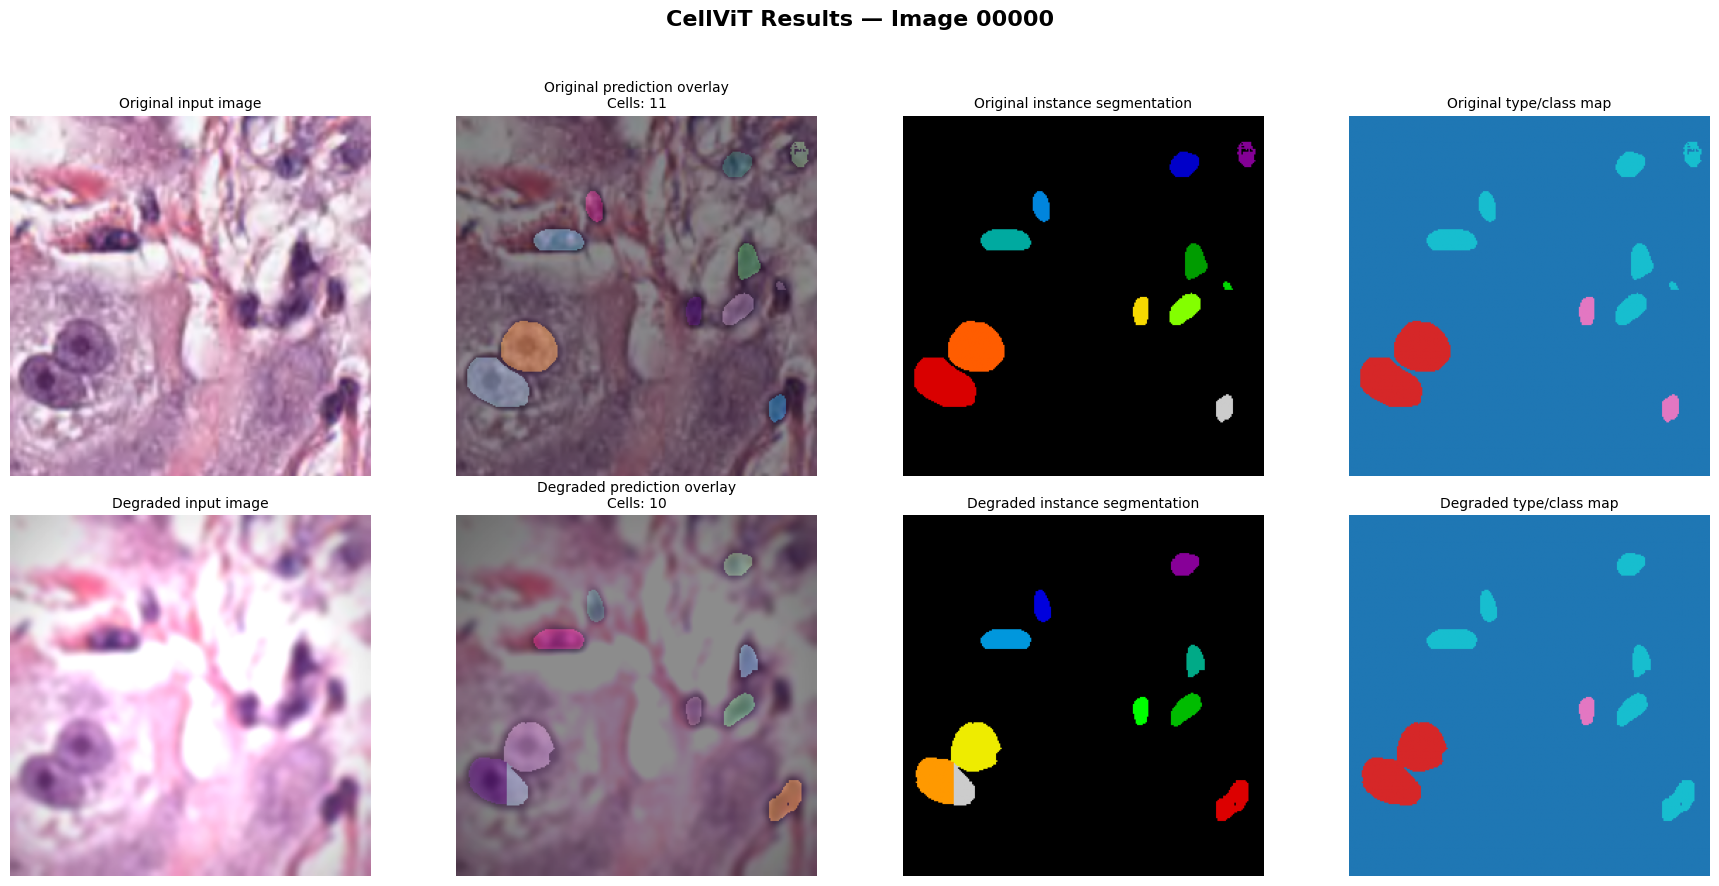

Original prediction statistics:
{
  "image_name": "00000.png",
  "height": 256,
  "width": 256,
  "num_cells": 11,
  "num_classes": 3,
  "cell_classes": [
    0,
    1,
    2,
    3
  ],
  "runtime_seconds": 0.3851
}

Degraded prediction statistics:
{
  "image_name": "00000.png",
  "height": 256,
  "width": 256,
  "num_cells": 10,
  "num_classes": 3,
  "cell_classes": [
    0,
    1,
    2,
    3
  ],
  "runtime_seconds": 0.3986
}

Original class-map pixel counts:
{1: 2296, 2: 380, 3: 1813}

Degraded class-map pixel counts:
{1: 2018, 2: 182, 3: 1895}

IMAGE ID: 00001


,Version,Detected cells,Reported classes,Runtime (s),Detected class IDs
0,Original,17,3,0.3915,"[0, 1, 2, 3]"
1,Degraded,15,3,0.3879,"[0, 1, 2, 3]"


Change in detected cells: -2
Cell-count reduction: 11.76%


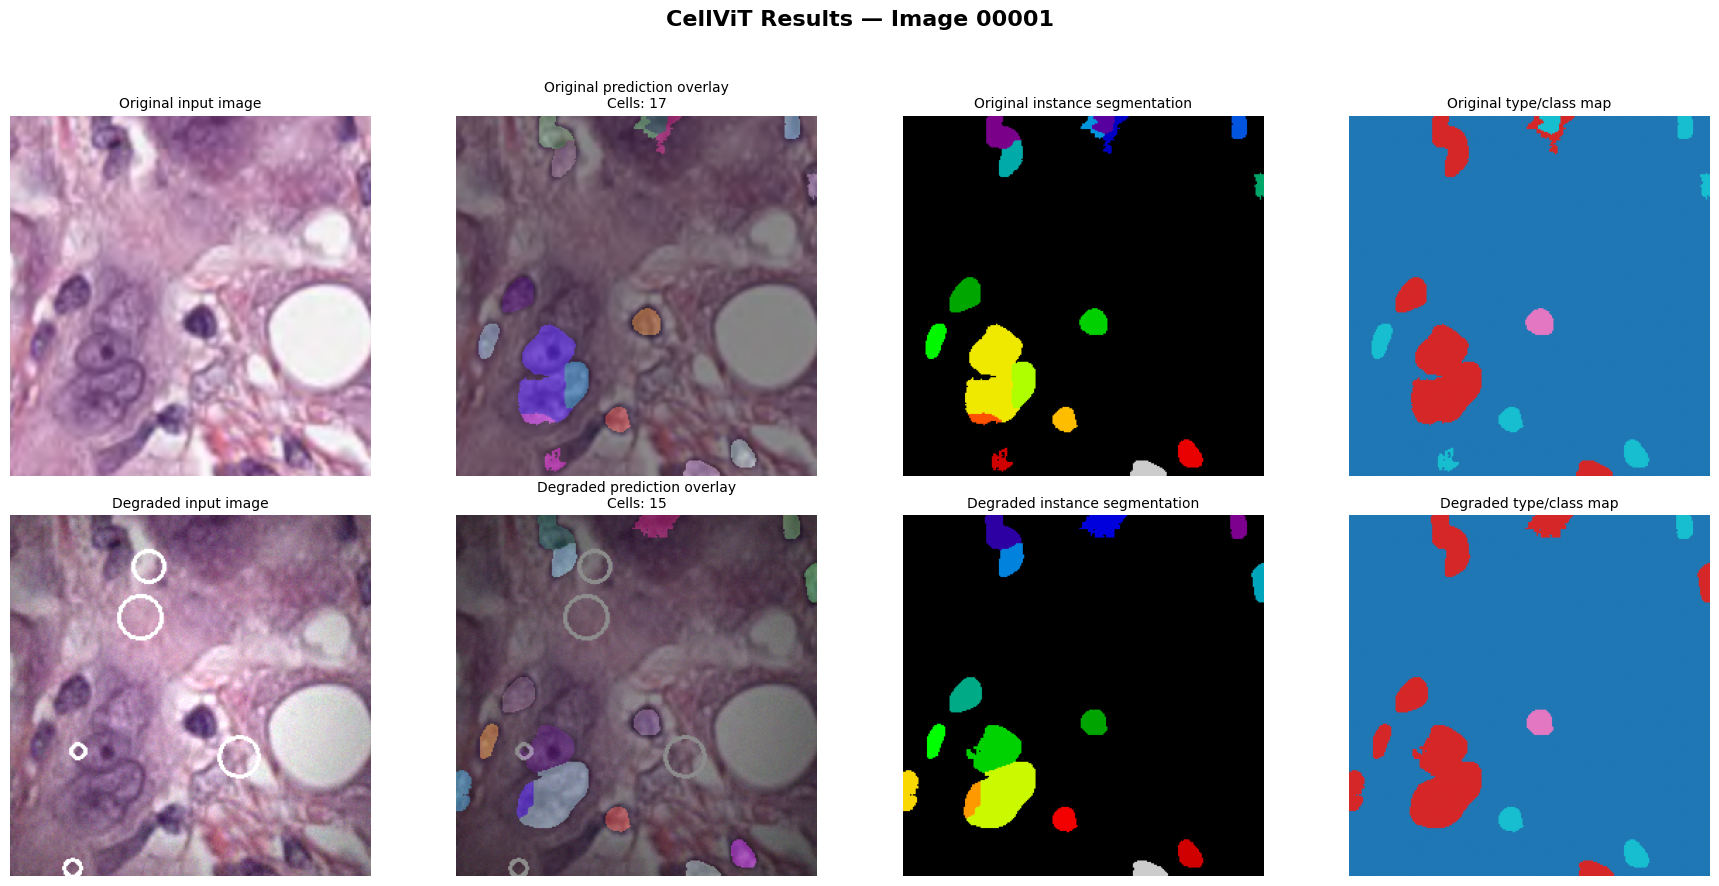

Original prediction statistics:
{
  "image_name": "00001.png",
  "height": 256,
  "width": 256,
  "num_cells": 17,
  "num_classes": 3,
  "cell_classes": [
    0,
    1,
    2,
    3
  ],
  "runtime_seconds": 0.3915
}

Degraded prediction statistics:
{
  "image_name": "00001.png",
  "height": 256,
  "width": 256,
  "num_cells": 15,
  "num_classes": 3,
  "cell_classes": [
    0,
    1,
    2,
    3
  ],
  "runtime_seconds": 0.3879
}

Original class-map pixel counts:
{1: 4080, 2: 301, 3: 1358}

Degraded class-map pixel counts:
{1: 4984, 2: 281, 3: 697}

IMAGE ID: 00002


,Version,Detected cells,Reported classes,Runtime (s),Detected class IDs
0,Original,13,3,0.3885,"[0, 1, 2, 3]"
1,Degraded,5,1,0.3886,"[0, 3]"


Change in detected cells: -8
Cell-count reduction: 61.54%


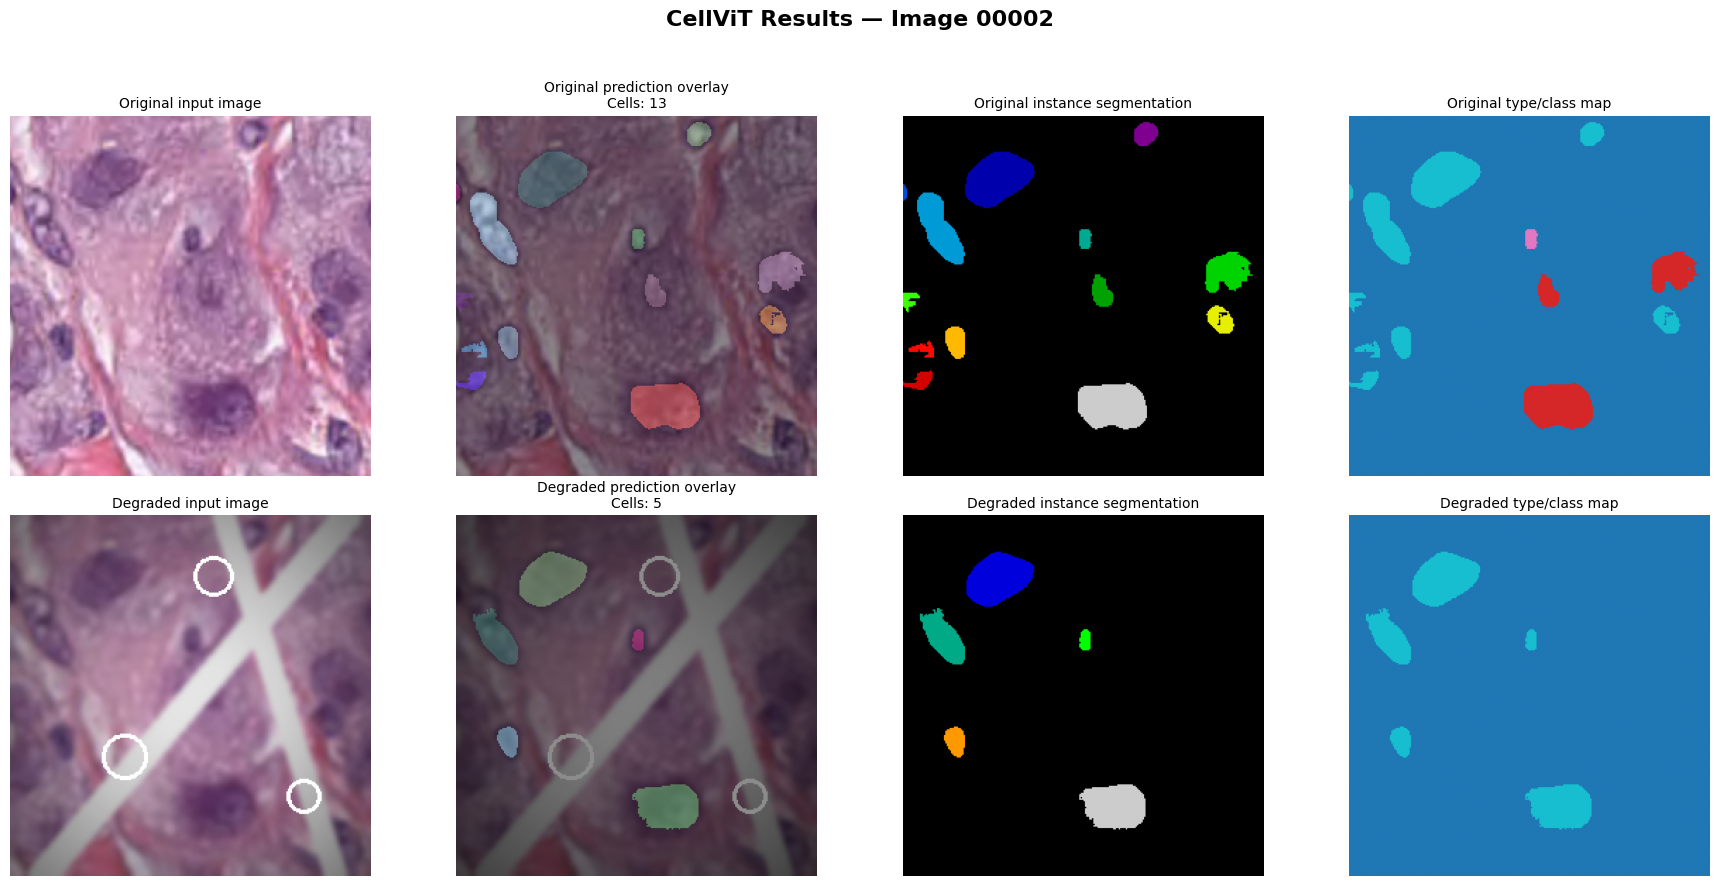

Original prediction statistics:
{
  "image_name": "00002.png",
  "height": 256,
  "width": 256,
  "num_cells": 13,
  "num_classes": 3,
  "cell_classes": [
    0,
    1,
    2,
    3
  ],
  "runtime_seconds": 0.3885
}

Degraded prediction statistics:
{
  "image_name": "00002.png",
  "height": 256,
  "width": 256,
  "num_cells": 5,
  "num_classes": 1,
  "cell_classes": [
    0,
    3
  ],
  "runtime_seconds": 0.3886
}

Original class-map pixel counts:
{1: 2268, 2: 110, 3: 3420}

Degraded class-map pixel counts:
{3: 3549}

IMAGE ID: 00003


,Version,Detected cells,Reported classes,Runtime (s),Detected class IDs
0,Original,11,2,0.3900,"[0, 1, 3]"
1,Degraded,9,2,0.3716,"[0, 1, 3]"


Change in detected cells: -2
Cell-count reduction: 18.18%


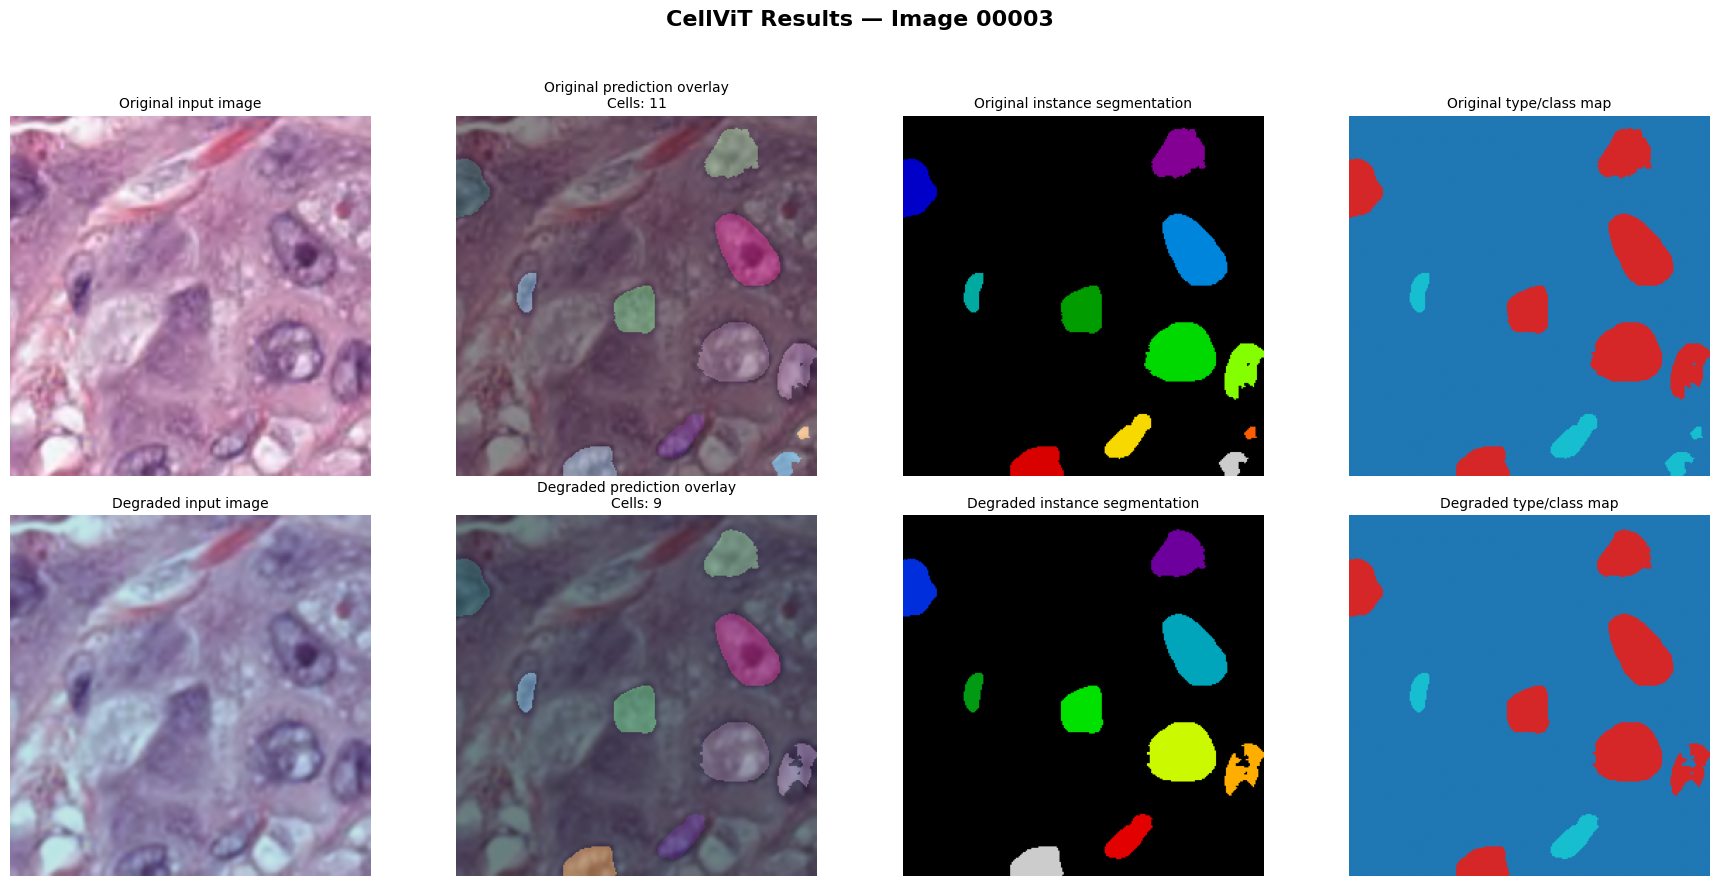

Original prediction statistics:
{
  "image_name": "00003.png",
  "height": 256,
  "width": 256,
  "num_cells": 11,
  "num_classes": 2,
  "cell_classes": [
    0,
    1,
    3
  ],
  "runtime_seconds": 0.39
}

Degraded prediction statistics:
{
  "image_name": "00003.png",
  "height": 256,
  "width": 256,
  "num_cells": 9,
  "num_classes": 2,
  "cell_classes": [
    0,
    1,
    3
  ],
  "runtime_seconds": 0.3716
}

Original class-map pixel counts:
{1: 7159, 3: 1108}

Degraded class-map pixel counts:
{1: 6942, 3: 860}


In [ ]:

# ============================================================
# CellViT Visual Comparison Dashboard
# Original vs Degraded: Images, Segmentation, Classification
# Existing predictions only — NO inference is performed.
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter
from IPython.display import display

# -------------------- PATHS --------------------
PROJECT = "/content/drive/MyDrive/AI_Readiness_Project"

RESULTS = os.path.join(PROJECT, "CellViT_Results")
ORIG_PRED = os.path.join(RESULTS, "Original_Predictions")
DEG_PRED = os.path.join(RESULTS, "Degraded_Predictions")

# Your existing dataset folder
DATASET = os.path.join(PROJECT, "AI_Readiness_Dataset (1)")

# Choose image IDs to visualize
IMAGE_IDS = ["00000", "00001", "00002", "00003"]

# -------------------- HELPER FUNCTIONS --------------------

def find_image(folder, image_id):
    """Find an image file whose filename matches the image ID."""
    if not os.path.isdir(folder):
        return None

    extensions = (".png", ".jpg", ".jpeg", ".tif", ".tiff")
    matches = []

    for root, _, files in os.walk(folder):
        for filename in files:
            stem = os.path.splitext(filename)[0]
            if stem == image_id and filename.lower().endswith(extensions):
                matches.append(os.path.join(root, filename))

    # Prefer an exact ID match in case multiple copies exist
    return matches[0] if matches else None


def find_source_image(split_name, image_id):
    """Search the original/degraded image folders."""
    candidates = [
        os.path.join(DATASET, split_name),
        os.path.join(PROJECT, "AI_Readiness_Dataset", split_name),
    ]

    for folder in candidates:
        path = find_image(folder, image_id)
        if path:
            return path

    return None


def load_json(path):
    if os.path.isfile(path):
        try:
            with open(path, "r") as f:
                return json.load(f)
        except Exception:
            pass
    return {}


def load_npy(path):
    if os.path.isfile(path):
        try:
            return np.load(path, allow_pickle=True)
        except Exception as e:
            print(f"Could not load {path}: {e}")
    return None


def load_rgb(path):
    if path and os.path.isfile(path):
        try:
            return np.array(Image.open(path).convert("RGB"))
        except Exception:
            pass
    return None


def show_panel(ax, image, title, cmap=None):
    ax.set_title(title, fontsize=10)
    ax.axis("off")

    if image is None:
        ax.text(
            0.5, 0.5, "Image/file unavailable",
            ha="center", va="center", wrap=True
        )
    elif image.ndim == 2:
        ax.imshow(image, cmap=cmap or "viridis")
    else:
        ax.imshow(image)


def summarize_type_map(type_map):
    """Count predicted pixels belonging to each non-background type."""
    if type_map is None:
        return "Type map unavailable"

    values, counts = np.unique(type_map, return_counts=True)
    parts = [
        f"Class {int(v)}: {int(c):,} px"
        for v, c in zip(values, counts)
        if v != 0
    ]
    return "\n".join(parts) if parts else "No non-background classes"


def get_class_counts(type_map):
    """Summarize class pixels; this is not a cell-level classification score."""
    if type_map is None:
        return {}
    values, counts = np.unique(type_map, return_counts=True)
    return {
        int(v): int(c)
        for v, c in zip(values, counts)
        if v != 0
    }


# -------------------- DASHBOARD --------------------

for image_id in IMAGE_IDS:

    print("\n" + "=" * 90)
    print(f"IMAGE ID: {image_id}")
    print("=" * 90)

    original_dir = os.path.join(ORIG_PRED, image_id)
    degraded_dir = os.path.join(DEG_PRED, image_id)

    # Prediction outputs already saved by CellViT
    original_stats = load_json(
        os.path.join(original_dir, "statistics.json")
    )
    degraded_stats = load_json(
        os.path.join(degraded_dir, "statistics.json")
    )

    original_instance = load_npy(
        os.path.join(original_dir, "instance_map.npy")
    )
    degraded_instance = load_npy(
        os.path.join(degraded_dir, "instance_map.npy")
    )

    original_type = load_npy(
        os.path.join(original_dir, "type_map.npy")
    )
    degraded_type = load_npy(
        os.path.join(degraded_dir, "type_map.npy")
    )

    original_overlay = load_rgb(
        os.path.join(original_dir, "overlay.png")
    )
    degraded_overlay = load_rgb(
        os.path.join(degraded_dir, "overlay.png")
    )

    # Find source images. Folder names are assumed to be original/degraded.
    original_image_path = find_source_image("original", image_id)
    degraded_image_path = find_source_image("degraded", image_id)

    original_image = load_rgb(original_image_path)
    degraded_image = load_rgb(degraded_image_path)

    # --------- Numerical summary ---------
    original_cells = original_stats.get("num_cells", None)
    degraded_cells = degraded_stats.get("num_cells", None)

    if original_cells is not None and degraded_cells is not None:
        change = degraded_cells - original_cells
        reduction = (
            100 * (original_cells - degraded_cells) / original_cells
            if original_cells else np.nan
        )
    else:
        change, reduction = None, np.nan

    summary = pd.DataFrame([
        {
            "Version": "Original",
            "Detected cells": original_cells,
            "Reported classes": original_stats.get("num_classes"),
            "Runtime (s)": original_stats.get("runtime_seconds"),
            "Detected class IDs": original_stats.get("cell_classes"),
        },
        {
            "Version": "Degraded",
            "Detected cells": degraded_cells,
            "Reported classes": degraded_stats.get("num_classes"),
            "Runtime (s)": degraded_stats.get("runtime_seconds"),
            "Detected class IDs": degraded_stats.get("cell_classes"),
        },
    ])

    display(summary)

    if change is not None:
        print(f"Change in detected cells: {change:+d}")
        print(f"Cell-count reduction: {reduction:.2f}%")

    # --------- Visual comparison ---------
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    fig.suptitle(
        f"CellViT Results — Image {image_id}",
        fontsize=16, fontweight="bold"
    )

    # Top row: Original
    show_panel(
        axes[0, 0], original_image,
        "Original input image"
    )
    show_panel(
        axes[0, 1], original_overlay,
        f"Original prediction overlay\n"
        f"Cells: {original_cells}"
    )
    show_panel(
        axes[0, 2], original_instance,
        "Original instance segmentation",
        cmap="nipy_spectral"
    )
    show_panel(
        axes[0, 3], original_type,
        "Original type/class map",
        cmap="tab10"
    )

    # Bottom row: Degraded
    show_panel(
        axes[1, 0], degraded_image,
        "Degraded input image"
    )
    show_panel(
        axes[1, 1], degraded_overlay,
        f"Degraded prediction overlay\n"
        f"Cells: {degraded_cells}"
    )
    show_panel(
        axes[1, 2], degraded_instance,
        "Degraded instance segmentation",
        cmap="nipy_spectral"
    )
    show_panel(
        axes[1, 3], degraded_type,
        "Degraded type/class map",
        cmap="tab10"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

    # --------- Classification details ---------
    print("Original prediction statistics:")
    print(json.dumps(original_stats, indent=2))

    print("\nDegraded prediction statistics:")
    print(json.dumps(degraded_stats, indent=2))

    print("\nOriginal class-map pixel counts:")
    print(get_class_counts(original_type))

    print("\nDegraded class-map pixel counts:")
    print(get_class_counts(degraded_type))

    # --------- Optional saved per-image readiness metrics ---------
    # This only looks for a target CSV that already exists.
    target_candidates = [
        os.path.join(
            PROJECT, "AI_Readiness_Dataset", "Targets",
            "AI_Readiness_Targets_FINAL.csv"
        ),
        os.path.join(
            PROJECT, "AI_Readiness_Dataset", "Targets",
            "AI_Readiness_Targets_CORRECTED.csv"
        ),
        os.path.join(
            PROJECT, "AI_Readiness_Dataset", "Targets",
            "AI_Readiness_Targets.csv"
        ),
    ]

    for csv_path in target_candidates:
        if os.path.isfile(csv_path):
            try:
                targets = pd.read_csv(csv_path)
                id_col = next(
                    (c for c in ["image_id", "image_name", "Image_ID"]
                     if c in targets.columns),
                    None
                )

                if id_col:
                    target_row = targets[
                        targets[id_col].astype(str).str.replace(
                            ".png", "", regex=False
                        ).str.zfill(5) == image_id
                    ]

                    if not target_row.empty:
                        print(f"\nExisting readiness metrics: {image_id}")
                        display(target_row)
                        break
            except Exception as e:
                print("Could not read target CSV:", e)
